# Kinematic Task Transformer — kết quả và kiểm chứng

Notebook chỉ đọc artifacts, không train lại. “Motor-invariant” là giả thuyết. Chỉ coi hoàn thành khi `results/task_transformer/validation.json` có `complete: true`. Bảng số được đặt trước hình. [Báo cáo tiếng Việt](../results/task_transformer/REPORT_VI.md).

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if not (ROOT/'results/task_transformer').exists(): ROOT=ROOT.parent
OUT=ROOT/'results/task_transformer'
TABLES=OUT/'tables'
pd.set_option('display.max_columns',40)
pd.set_option('display.max_rows',100)
pd.set_option('display.precision',6)
def read(name):return pd.read_csv(TABLES/(name+'.csv'))
validation=json.loads((OUT/'numeric_validation.json').read_text())
assert validation['complete']
for rel,digest in {**validation['artifact_sha256'],**validation['code_sha256']}.items():
    assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest()==digest,rel
display(pd.DataFrame([validation['checks']]))

,protected_files,participants,outer_folds,inner_neural_fits,outer_model_records,ig_artifacts_validated,permutation_evaluations_replayed,baseline_oof_matches,nested_selection_train_only,preprocessing_train_only,raw_feature_bank_verified,robustness_and_missing_task_predictions_replayed
0,686,258,6,432,180,108,12480,True,True,True,True,True


## Bảng kết quả cuối cùng — seed42

OOF tính trên258 người, mean±SD tính từ6 outer folds. SD không phải confidence interval. `nested_selected` được chọn hoàn toàn trong inner CV; các family khác là ablation.

In [2]:
d=read('ablation_primary')
display(d[['model','accuracy','f1_macro','auc','balanced_accuracy','mean_f1_macro','std_f1_macro','parameters_mean','task_count_mean']])
display(d[['model','mean_accuracy','std_accuracy','mean_f1_macro','std_f1_macro','mean_auc','std_auc','mean_balanced_accuracy','std_balanced_accuracy']])

,model,accuracy,f1_macro,auc,balanced_accuracy,mean_f1_macro,std_f1_macro,parameters_mean,task_count_mean
0,lightgbm,0.848837,0.847163,0.906902,0.847461,0.847047,0.032387,NaN,14.0
1,lightgbm_without_text,0.697674,0.692951,0.769717,0.692369,0.691750,0.041206,NaN,12.0
2,matched_task_mlp,0.755814,0.749488,0.825479,0.747370,0.747685,0.048320,6817.000000,14.0
3,matched_transformer_no_type,0.751938,0.745185,0.814108,0.743022,0.743463,0.039667,11041.000000,14.0
4,matched_transformer_type,0.701550,0.693023,0.776893,0.691608,0.686600,0.075643,11489.000000,14.0
5,motor_normalized,0.728682,0.723887,0.798480,0.722894,0.717164,0.089516,17057.666667,14.0
6,task_mlp,0.751938,0.745828,0.820310,0.743874,0.744018,0.047931,6891.666667,14.0
7,train_augmented,0.744186,0.741137,0.798662,0.741137,0.737360,0.070550,21985.166667,14.0
8,transformer,0.744186,0.738514,0.815749,0.736881,0.735875,0.038768,15761.000000,14.0
9,without_text_tasks,0.709302,0.701771,0.764184,0.700304,0.700558,0.049617,15835.666667,12.0


,model,mean_accuracy,std_accuracy,mean_f1_macro,std_f1_macro,mean_auc,std_auc,mean_balanced_accuracy,std_balanced_accuracy
0,lightgbm,0.848837,0.032056,0.847047,0.032387,0.904027,0.031284,0.847276,0.032343
1,lightgbm_without_text,0.697674,0.041601,0.691750,0.041206,0.769022,0.056782,0.692620,0.041745
2,matched_task_mlp,0.755814,0.043508,0.747685,0.048320,0.834557,0.049000,0.747322,0.046811
3,matched_transformer_no_type,0.751938,0.035013,0.743463,0.039667,0.829167,0.036235,0.743814,0.040240
4,matched_transformer_type,0.701550,0.071174,0.686600,0.075643,0.781293,0.104164,0.693238,0.072088
5,motor_normalized,0.728682,0.081451,0.717164,0.089516,0.836057,0.073664,0.722866,0.089550
6,task_mlp,0.751938,0.043300,0.744018,0.047931,0.828344,0.046830,0.743850,0.046564
7,train_augmented,0.744186,0.067402,0.737360,0.070550,0.814502,0.052886,0.741694,0.068791
8,transformer,0.744186,0.036028,0.735875,0.038768,0.828436,0.035965,0.737783,0.038239
9,without_text_tasks,0.709302,0.050417,0.700558,0.049617,0.782072,0.054164,0.701050,0.050690


## So sánh paired và các đối chứng cùng cấu hình

Corrected/harmed dùng cùng participant so với baseline LightGBM. Matched controls không tham gia chọn nested winner; số tham số MLP và attention vẫn khác nhau.

In [3]:
display(read('paired_comparisons'))
display(read('matched_ablation'))

,model,corrected,harmed,unchanged_correct,unchanged_wrong,mean_delta_f1_macro,std_delta_f1_macro,mean_delta_accuracy,std_delta_accuracy,mean_delta_auc,std_delta_auc,mean_delta_balanced_accuracy,std_delta_balanced_accuracy
0,lightgbm,0,0,219,39,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,lightgbm_without_text,12,51,168,27,-0.155297,0.042329,-0.151163,0.040946,-0.135005,0.063610,-0.154656,0.045046
2,matched_task_mlp,24,48,171,15,-0.099362,0.053329,-0.093023,0.053031,-0.069470,0.047032,-0.099954,0.051649
3,matched_transformer_no_type,24,49,170,15,-0.103584,0.019385,-0.096899,0.017506,-0.074860,0.030318,-0.103463,0.020267
4,matched_transformer_type,23,61,158,16,-0.160446,0.086318,-0.147287,0.086600,-0.122734,0.082692,-0.154038,0.084112
5,motor_normalized,23,54,165,16,-0.129883,0.080347,-0.120155,0.074152,-0.067970,0.095820,-0.124410,0.078928
6,task_mlp,23,48,171,16,-0.103029,0.053923,-0.096899,0.053875,-0.075683,0.053354,-0.103426,0.052330
7,train_augmented,24,51,168,15,-0.109686,0.050524,-0.104651,0.050417,-0.089525,0.059210,-0.105583,0.047374
8,transformer,23,50,169,16,-0.111171,0.010012,-0.104651,0.012738,-0.075591,0.029916,-0.109493,0.010744
9,without_text_tasks,21,57,162,18,-0.146488,0.058065,-0.139535,0.060644,-0.121955,0.055436,-0.146226,0.058373


,comparison,model,reference,oof_delta_f1_macro,mean_delta_f1_macro,std_delta_f1_macro,oof_delta_accuracy,mean_delta_accuracy,std_delta_accuracy,oof_delta_auc,mean_delta_auc,std_delta_auc,oof_delta_balanced_accuracy,mean_delta_balanced_accuracy,std_delta_balanced_accuracy
0,self_attention,matched_transformer_no_type,matched_task_mlp,-0.004302,-0.004222,0.062093,-0.003876,-0.003876,0.057751,-0.011371,-0.005390,0.040391,-0.004348,-0.003509,0.060786
1,task_type_embedding,matched_transformer_type,matched_transformer_no_type,-0.052162,-0.056863,0.087733,-0.050388,-0.050388,0.087532,-0.037215,-0.047874,0.074416,-0.051414,-0.050575,0.086030
2,motor_normalization,matched_motor_normalized,matched_transformer_no_type,-0.046291,-0.050921,0.079991,-0.046512,-0.046512,0.072056,-0.039100,-0.029659,0.062015,-0.045363,-0.046350,0.077528
3,training_augmentation,matched_train_augmented,matched_transformer_no_type,0.037640,0.036536,0.039074,0.034884,0.034884,0.035269,0.020614,0.020423,0.028798,0.038279,0.037902,0.036235
4,train_only_task_selection,matched_xai_selected,matched_transformer_type,-0.007158,-0.004850,0.068816,-0.007752,-0.007752,0.068463,-0.028945,-0.039718,0.029321,-0.006993,-0.007383,0.064137


## Từng fold, cấu hình đã chọn và sensitivity theo seed

Seeds43/44 giữ hyperparameters chọn bằng seed42; không phải cohort độc lập.

In [4]:
display(read('fold_results').query('seed==42').sort_values(['model','fold']))
display(read('selected_configurations'))
display(read('seed_sensitivity_summary'))

,model,seed,fold,accuracy,f1_macro,auc,balanced_accuracy
0,lightgbm,42,0,0.837209,0.836856,0.895652,0.838043
27,lightgbm,42,1,0.860465,0.858553,0.960526,0.858553
54,lightgbm,42,2,0.837209,0.835788,0.901316,0.837719
81,lightgbm,42,3,0.906977,0.905702,0.899123,0.905702
108,lightgbm,42,4,0.813953,0.811404,0.864035,0.811404
135,lightgbm,42,5,0.837209,0.833977,0.903509,0.832237
3,lightgbm_without_text,42,0,0.627907,0.622807,0.739130,0.622826
30,lightgbm_without_text,42,1,0.697674,0.686835,0.776316,0.685307
57,lightgbm_without_text,42,2,0.674419,0.672826,0.688596,0.675439
84,lightgbm_without_text,42,3,0.744186,0.739106,0.861842,0.737939


,fold,family,candidate,epochs,inner_f1,inner_auc,source_model
0,0,task_mlp,0,23.0,0.713120,0.783249,NaN
1,0,transformer,0,16.0,0.747720,0.768002,NaN
2,0,motor_normalized,0,12.0,0.692668,0.735585,NaN
3,0,xai_selected,3,23.0,0.712443,0.787223,NaN
4,0,train_augmented,0,18.0,0.719167,0.762433,NaN
5,0,without_text_tasks,0,16.0,0.680318,0.722001,NaN
6,0,nested_selected,0,NaN,NaN,NaN,transformer
7,1,task_mlp,1,35.0,0.728288,0.790231,NaN
8,1,transformer,0,12.0,0.716638,0.777744,NaN
9,1,motor_normalized,0,15.0,0.742703,0.832158,NaN


,model,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,auc_mean,auc_std,balanced_accuracy_mean,balanced_accuracy_std
0,lightgbm,0.847163,0.000000,0.848837,0.000000,0.906902,0.000000,0.847461,0.000000
1,lightgbm_without_text,0.692951,0.000000,0.697674,0.000000,0.769717,0.000000,0.692369,0.000000
2,motor_normalized,0.714105,0.011923,0.718346,0.011841,0.795885,0.002783,0.713570,0.011867
3,nested_selected,0.717110,0.013734,0.720930,0.013975,0.782122,0.014650,0.716753,0.013435
4,task_mlp,0.741108,0.009708,0.746770,0.008951,0.821101,0.015552,0.739495,0.009878
5,train_augmented,0.741393,0.016073,0.744186,0.015504,0.809506,0.015150,0.741705,0.016547
6,transformer,0.739259,0.008456,0.744186,0.007752,0.811675,0.005985,0.738016,0.008751
7,without_text_tasks,0.690467,0.009845,0.697674,0.010255,0.765643,0.006270,0.689247,0.009618
8,xai_selected,0.752644,0.021052,0.755814,0.020510,0.830121,0.010757,0.752478,0.021282


## Nuisance và thiếu tác vụ

Không chọn lại model từ stress. Translation/scale/pressure/time có thể làm mất thông tin hữu ích; không mặc định label-preserving. Neural dùng token masks; cây dùng Train medians.

In [5]:
display(read('robustness_summary'))
display(read('masking_summary'))

,model,condition,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,auc_mean,auc_std,balanced_accuracy_mean,balanced_accuracy_std,delta_f1_macro_mean,delta_f1_macro_std,delta_accuracy_mean,delta_accuracy_std,delta_auc_mean,delta_auc_std,delta_balanced_accuracy_mean,delta_balanced_accuracy_std,mean_absolute_probability_shift_mean,mean_absolute_probability_shift_std,attribution_rank_spearman_mean,attribution_rank_spearman_std
0,lightgbm,duration_scale,0.833550,0.058176,0.837209,0.056965,0.899682,0.044154,0.831272,0.057468,-0.013497,0.041771,-1.162791e-02,0.040946,-0.004345,0.016397,-0.016004,0.040091,5.047891e-02,1.493898e-02,0.991209,0.008340
1,lightgbm,pressure_scale,0.846869,0.032457,0.848837,0.032056,0.905111,0.032600,0.846733,0.032556,-0.000178,0.000436,0.000000e+00,0.000000,0.001084,0.005986,-0.000543,0.001331,1.028169e-02,3.382362e-03,0.997070,0.005323
2,lightgbm,sampling_half,0.598004,0.112889,0.666667,0.071553,0.851487,0.052108,0.633000,0.076874,-0.249043,0.110103,-1.821705e-01,0.069638,-0.052539,0.036108,-0.214277,0.077235,2.483301e-01,8.690739e-02,0.955311,0.025992
3,lightgbm,spatial_scale,0.768633,0.069181,0.786822,0.059594,0.897086,0.032415,0.766840,0.063792,-0.078414,0.043067,-6.201550e-02,0.035013,-0.006941,0.019290,-0.080436,0.037832,1.432736e-01,4.063589e-02,0.990476,0.010183
4,lightgbm,timing_warp,0.820357,0.028520,0.821705,0.028164,0.896380,0.026606,0.822496,0.029755,-0.026689,0.035078,-2.713178e-02,0.034232,-0.007647,0.013753,-0.024781,0.036382,5.740655e-02,1.073294e-02,0.991941,0.008972
5,lightgbm,translation,0.826090,0.038475,0.829457,0.037977,0.905842,0.033451,0.824109,0.037976,-0.020956,0.023516,-1.937984e-02,0.022865,0.001815,0.007114,-0.023168,0.023916,2.743846e-02,1.105323e-02,0.996337,0.008972
6,lightgbm_without_text,duration_scale,0.717180,0.074190,0.720930,0.074998,0.779246,0.077563,0.717803,0.073117,0.025431,0.047749,2.325581e-02,0.046512,0.010224,0.022048,0.025183,0.047745,5.409414e-02,1.409044e-02,NaN,NaN
7,lightgbm_without_text,pressure_scale,0.696703,0.042140,0.705426,0.043300,0.765001,0.052648,0.696823,0.042323,0.004954,0.012040,7.751938e-03,0.012009,-0.004020,0.016435,0.004203,0.011170,2.980635e-02,1.026479e-02,NaN,NaN
8,lightgbm_without_text,sampling_half,0.511981,0.092529,0.616279,0.048224,0.732774,0.054648,0.576352,0.051186,-0.179769,0.068690,-8.139535e-02,0.032056,-0.036248,0.056771,-0.116268,0.039524,2.631681e-01,5.931353e-02,NaN,NaN
9,lightgbm_without_text,spatial_scale,0.691218,0.038794,0.697674,0.038914,0.774142,0.044450,0.691706,0.039573,-0.000532,0.013874,1.676899e-17,0.014708,0.005120,0.017303,-0.000914,0.013365,2.571892e-02,7.592961e-03,NaN,NaN


,model,kind,drop_f1_macro_mean,drop_f1_macro_std,drop_accuracy_mean,drop_accuracy_std,drop_auc_mean,drop_auc_std,drop_balanced_accuracy_mean,drop_balanced_accuracy_std
0,lightgbm,missing_2,0.037790,0.017517,0.037209,0.017026,0.027674,0.019943,0.037143,0.017627
1,lightgbm,missing_4,0.055888,0.017669,0.053488,0.019402,0.038872,0.015235,0.054762,0.016290
2,lightgbm,missing_6,0.107901,0.038944,0.101938,0.036812,0.091344,0.039704,0.103198,0.034834
3,lightgbm,one_task,0.020738,0.013073,0.020210,0.013097,0.008976,0.007126,0.020500,0.012748
4,lightgbm,without_text_diagnostic,0.175000,0.069624,0.170543,0.068463,0.177441,0.090664,0.175521,0.070692
5,lightgbm_without_text,missing_2,0.004335,0.036371,0.001938,0.033132,0.009790,0.017115,0.003399,0.036040
6,lightgbm_without_text,missing_4,0.008640,0.048975,0.006977,0.045690,0.020448,0.023887,0.008053,0.048235
7,lightgbm_without_text,missing_6,0.034848,0.042557,0.027907,0.038071,0.032066,0.013633,0.027457,0.047979
8,lightgbm_without_text,one_task,0.001136,0.023289,0.000277,0.022321,0.003842,0.008180,0.000769,0.023268
9,lightgbm_without_text,without_text_diagnostic,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


## Task/group attribution — held-out models

IG giải thích positive-class logit, reference Train mean. TreeSHAP và IG khác reference; so sánh rank/share, không gán ý nghĩa nhân quả.

In [6]:
d=read('attribution_importance')
display(d.query("level=='task'").sort_values(['model','rank']).groupby('model').head(5))
display(d.query("level=='group'").sort_values(['model','rank']).groupby('model').head(5))

,model,level,block,n_features,mean_absolute_mass,share_percent,mass_per_feature,rank,fold_sd,mean_signed
13,lightgbm,task,copy,74,4.297703,35.341398,0.058077,1.0,0.120311,-0.087086
2,lightgbm,task,dictation,74,1.363045,11.208761,0.018420,2.0,0.225283,0.002930
7,lightgbm,task,lower-loops-fast,74,1.014206,8.340140,0.013705,3.0,0.207969,-0.017777
4,lightgbm,task,small-spiral-fast,74,0.894051,7.352066,0.012082,4.0,0.148123,-0.016040
1,lightgbm,task,RCFT-recall,74,0.868699,7.143591,0.011739,5.0,0.241988,-0.015772
91,motor_normalized,task,copy,74,4.170460,13.487478,0.056358,1.0,1.999042,0.068304
80,motor_normalized,task,dictation,74,2.663342,8.613380,0.035991,2.0,0.737325,0.009580
86,motor_normalized,task,rainbow-fast,74,2.524045,8.162889,0.034109,3.0,0.746540,0.021777
85,motor_normalized,task,lower-loops-fast,74,2.348147,7.594024,0.031732,4.0,0.710157,-0.016567
78,motor_normalized,task,RCFT-recognition,74,2.185417,7.067748,0.029533,5.0,0.674824,-0.030043


,model,level,block,n_features,mean_absolute_mass,share_percent,mass_per_feature,rank,fold_sd,mean_signed
25,lightgbm,group,fft,224,3.400340,27.962093,0.015180,1.0,0.373143,-0.080664
23,lightgbm,group,statistics,140,2.625793,21.592747,0.018756,2.0,0.267184,-0.034254
21,lightgbm,group,trajectory,112,2.465493,20.274545,0.022013,3.0,0.251436,-0.002830
20,lightgbm,group,orientation,56,1.039268,8.546238,0.018558,4.0,0.262061,-0.010945
19,lightgbm,group,pressure,112,0.589001,4.843548,0.005259,5.0,0.132189,-0.038467
103,motor_normalized,group,fft,224,8.051355,26.038485,0.035944,1.0,2.854857,-0.358755
101,motor_normalized,group,statistics,140,4.467235,14.447262,0.031909,2.0,0.820318,0.249595
97,motor_normalized,group,pressure,112,3.226258,10.433882,0.028806,3.0,1.142229,-0.024589
99,motor_normalized,group,trajectory,112,3.105576,10.043587,0.027728,4.0,0.656030,0.085275
93,motor_normalized,group,acceleration,84,2.497392,8.076689,0.029731,5.0,1.300050,0.023996


## Stability và faithfulness

Attention là phân tích phụ. Completeness không chứng minh clinical validity. Permutation và zero-feature ablation là kiểm tra độc lập của ranking.

In [7]:
display(read('attribution_stability').groupby(['model','level'])[['spearman','top3_jaccard']].agg(['mean','std']).reset_index())
display(read('faithfulness'))
display(read('xai_baseline_rank_comparison'))
display(read('attention_agreement'))

model  level  spearman           top3_jaccard          
                                   mean       std         mean       std
0             lightgbm  group  0.913287  0.044917     1.000000  0.000000
1             lightgbm   task  0.822125  0.063413     0.566667  0.175933
2     motor_normalized  group  0.909557  0.063129     0.633333  0.228869
3     motor_normalized   task  0.303736  0.466809     0.313333  0.269568
4             task_mlp  group  0.941725  0.039352     1.000000  0.000000
5             task_mlp   task  0.306667  0.270109     0.360000  0.154919
6      train_augmented  group  0.871795  0.068602     0.833333  0.243975
7      train_augmented   task  0.217582  0.288818     0.300000  0.207020
8          transformer  group  0.935198  0.034204     0.700000  0.253546
9          transformer   task  0.362344  0.185305     0.300000  0.207020
10  without_text_tasks  group  0.891375  0.060784     0.633333  0.228869
11  without_text_tasks   task  0.486344  0.173307     0.320000  0.152128
12        xai_selected  group  0.817249  0.096278     1.000000  0.000000
13        xai_selected   task  0.698310  0.139206     0.680000  0.280815

,model,level,comparison,spearman
0,lightgbm,task,attribution_vs_permutation,0.920879
1,lightgbm,task,attribution_vs_zero_feature_ablation,0.780220
2,lightgbm,group,attribution_vs_permutation,0.909091
3,task_mlp,task,attribution_vs_permutation,-0.217582
4,task_mlp,task,attribution_vs_zero_feature_ablation,0.156044
5,task_mlp,group,attribution_vs_permutation,0.860140
6,transformer,task,attribution_vs_permutation,0.635165
7,transformer,task,attribution_vs_zero_feature_ablation,0.604396
8,transformer,group,attribution_vs_permutation,0.790210
9,motor_normalized,task,attribution_vs_permutation,0.775824


,model,level,reference,spearman
0,task_mlp,task,lightgbm_shap,-0.296703
1,transformer,task,lightgbm_shap,0.367033
2,motor_normalized,task,lightgbm_shap,0.437363
3,xai_selected,task,lightgbm_shap,0.863736
4,train_augmented,task,lightgbm_shap,0.472527
5,without_text_tasks,task,lightgbm_shap,-0.325633
6,task_mlp,group,lightgbm_shap,0.804196
7,transformer,group,lightgbm_shap,0.699301
8,motor_normalized,group,lightgbm_shap,0.706294
9,xai_selected,group,lightgbm_shap,0.909091


,model,comparison,spearman
0,motor_normalized,incoming_attention_vs_IG,0.621978
1,train_augmented,incoming_attention_vs_IG,0.621978
2,transformer,incoming_attention_vs_IG,0.934066
3,without_text_tasks,incoming_attention_vs_IG,0.933921
4,xai_selected,incoming_attention_vs_IG,0.947253


## Learning diagnostics và chi phí

Neural chạy GPU, LightGBM CPU; inference gồm preprocessing từ cached features, không gồm raw extraction. Gap mô tả tại inner best epoch.

In [8]:
display(read('overfitting_diagnostics').groupby('family')[['best_epoch','loss_gap','train_accuracy','validation_accuracy']].mean().reset_index())
display(read('inference_cost').groupby('model').median(numeric_only=True).reset_index())
display(pd.DataFrame([json.loads((OUT/'cache/validation.json').read_text())]))

,family,best_epoch,loss_gap,train_accuracy,validation_accuracy
0,motor_normalized,15.388889,0.202091,0.845637,0.710825
1,task_mlp,16.694444,0.176032,0.825944,0.696327
2,train_augmented,16.013889,0.203410,0.840741,0.702761
3,transformer,15.319444,0.197029,0.830484,0.709953
4,without_text_tasks,9.680556,0.126013,0.752717,0.662428
5,xai_selected,14.652778,0.189482,0.833770,0.704502


,model,fold,n_test,median_inference_seconds,min_inference_seconds,repeats,timing_only_train_seconds
0,lightgbm,2.5,43.0,0.001664,0.001470,20.0,0.405479
1,lightgbm_without_text,2.5,43.0,0.001829,0.001454,20.0,NaN
2,motor_normalized,2.5,43.0,0.004832,0.004102,20.0,NaN
3,task_mlp,2.5,43.0,0.003528,0.002983,20.0,NaN
4,train_augmented,2.5,43.0,0.004112,0.003325,20.0,NaN
5,transformer,2.5,43.0,0.004797,0.003793,20.0,NaN
6,without_text_tasks,2.5,43.0,0.003842,0.003388,20.0,NaN
7,xai_selected,2.5,43.0,0.004935,0.004230,20.0,NaN


,complete,original_cache_exactly_reconstructed,subjects,tasks,transformed_banks,checked_raw_record_conditions,seconds,feature_bank_sha256,augmentation_use
0,True,True,258,14,19,21672,718.235602,6f382ff4d5e36b80ab78d2ad70435f403a9ac4bce5982f...,training banks may only be indexed with curren...


## OOF và ca minh họa

Mọi người có đúng một dự đoán/method/seed. Ca local chọn ID đầu tiên theo từ điển cho từng outcome, chỉ để minh họa hậu nghiệm.

In [9]:
oof=read('oof_predictions')
display(oof.groupby(['model','seed']).agg(n=('participant_id','size'),unique_ids=('participant_id','nunique')).reset_index())
display(read('local_cases'))
display(read('paired_participant_changes').query("model=='transformer'").head(20))

,model,seed,n,unique_ids
0,lightgbm,42,258,258
1,lightgbm,43,258,258
2,lightgbm,44,258,258
3,lightgbm_without_text,42,258,258
4,lightgbm_without_text,43,258,258
5,lightgbm_without_text,44,258,258
6,matched_motor_normalized,42,258,258
7,matched_task_mlp,42,258,258
8,matched_train_augmented,42,258,258
9,matched_transformer_no_type,42,258,258


,model,participant_id,label,fold,baseline_prediction,prediction,baseline_probability,probability,probability_delta,change,selection
0,transformer,BR5301,0,1,1,0,0.667433,0.091917,-0.575517,corrected,lexicographically first ID per paired outcome;...
1,transformer,BR10301,0,4,0,1,0.249635,0.642862,0.393227,harmed,lexicographically first ID per paired outcome;...
2,transformer,BR10304,0,2,0,0,0.008734,0.020763,0.012029,unchanged_correct,lexicographically first ID per paired outcome;...
3,transformer,BR2404,0,5,1,1,0.614726,0.512628,-0.102099,unchanged_wrong,lexicographically first ID per paired outcome;...


,model,participant_id,label,fold,baseline_prediction,prediction,baseline_probability,probability,probability_delta,change
2064,transformer,BR10301,0,4,0,1,0.249635,0.642862,0.393227,harmed
2065,transformer,BR10302,0,0,0,1,0.046320,0.713583,0.667263,harmed
2066,transformer,BR10304,0,2,0,0,0.008734,0.020763,0.012029,unchanged_correct
2067,transformer,BR10305,0,3,0,0,0.138935,0.497398,0.358462,unchanged_correct
2068,transformer,BR10306,1,5,1,1,0.996677,0.854049,-0.142628,unchanged_correct
2069,transformer,BR10403,0,0,0,1,0.025581,0.575626,0.550045,harmed
2070,transformer,BR10404,0,2,0,0,0.008390,0.119114,0.110724,unchanged_correct
2071,transformer,BR10405,0,3,0,0,0.376719,0.285407,-0.091313,unchanged_correct
2072,transformer,BR10406,1,0,1,1,0.991508,0.883709,-0.107799,unchanged_correct
2073,transformer,BR2401,0,3,0,0,0.028684,0.387566,0.358882,unchanged_correct


## Attribution từng participant

Xem cả corrected, harmed, đúng và sai. Signed values là đóng góp vào logit, không phải xác suất.

In [10]:
cases=read('local_cases'); a=read('participant_attributions')
for row in cases.itertuples():
    display(Markdown(f'**{row.participant_id} — {row.change}**'))
    display(a[(a.model=='transformer')&(a.participant_id==row.participant_id)].sort_values('absolute_mass',ascending=False))

**BR5301 — corrected**

,model,participant_id,fold,task,absolute_mass,signed_logit
7809,transformer,BR5301,1,lower-loops-precise,8.239745,-0.237356
7807,transformer,BR5301,1,combined-loops-fast,7.239293,-1.110724
7811,transformer,BR5301,1,copy,6.665717,-0.534670
7806,transformer,BR5301,1,rainbow-fast,6.619927,-0.564965
7810,transformer,BR5301,1,combined-loops-precise,5.927777,-0.057214
7802,transformer,BR5301,1,small-spiral-fast,5.649724,0.163374
7808,transformer,BR5301,1,small-spiral-precise,5.643440,0.282920
7799,transformer,BR5301,1,RCFT-recall,5.297281,-0.819324
7803,transformer,BR5301,1,saw-fast,4.887628,-0.756631
7804,transformer,BR5301,1,upper-loops-fast,4.667162,-0.368171


**BR10301 — harmed**

,model,participant_id,fold,task,absolute_mass,signed_logit
7229,transformer,BR10301,4,saw-fast,3.641911,-0.104171
7226,transformer,BR10301,4,dictation,3.195962,-0.109120
7231,transformer,BR10301,4,lower-loops-fast,2.199933,-0.140120
7232,transformer,BR10301,4,rainbow-fast,2.096334,-0.250148
7230,transformer,BR10301,4,upper-loops-fast,2.044449,-0.192151
7237,transformer,BR10301,4,copy,1.995349,0.053621
7225,transformer,BR10301,4,RCFT-recall,1.979837,0.274184
7224,transformer,BR10301,4,RCFT-recognition,1.958632,0.297431
7234,transformer,BR10301,4,small-spiral-precise,1.909685,-0.045658
7233,transformer,BR10301,4,combined-loops-fast,1.851645,-0.095981


**BR10304 — unchanged_correct**

,model,participant_id,fold,task,absolute_mass,signed_logit
7257,transformer,BR10304,2,saw-fast,3.695853,-2.640862
7265,transformer,BR10304,2,copy,2.810629,-0.942985
7252,transformer,BR10304,2,RCFT-recognition,1.674666,-0.291290
7254,transformer,BR10304,2,dictation,1.633407,-0.576777
7264,transformer,BR10304,2,combined-loops-precise,1.437252,-0.286841
7255,transformer,BR10304,2,big-spiral-fast,1.437241,0.322412
7259,transformer,BR10304,2,lower-loops-fast,1.415439,0.151133
7263,transformer,BR10304,2,lower-loops-precise,1.401169,0.212529
7253,transformer,BR10304,2,RCFT-recall,1.223696,0.063561
7262,transformer,BR10304,2,small-spiral-precise,1.124970,-0.357246


**BR2404 — unchanged_wrong**

,model,participant_id,fold,task,absolute_mass,signed_logit
7399,transformer,BR2404,5,lower-loops-fast,7.018566,-0.715533
7396,transformer,BR2404,5,small-spiral-fast,6.863043,-0.624829
7403,transformer,BR2404,5,lower-loops-precise,6.683513,-0.213951
7392,transformer,BR2404,5,RCFT-recognition,6.130324,-0.303728
7393,transformer,BR2404,5,RCFT-recall,5.592877,0.078980
7395,transformer,BR2404,5,big-spiral-fast,4.430584,0.035039
7400,transformer,BR2404,5,rainbow-fast,4.197961,-0.225389
7398,transformer,BR2404,5,upper-loops-fast,4.101370,-0.177744
7404,transformer,BR2404,5,combined-loops-precise,3.746351,0.159759
7397,transformer,BR2404,5,saw-fast,3.615131,-0.272545


## Hình phục vụ paper

PNG300dpi, SVG và manifest lưu riêng. Chú thích chi tiết trong report; attention đặt supplementary.

**01_architecture** — Actual architecture and nested selection protocol.

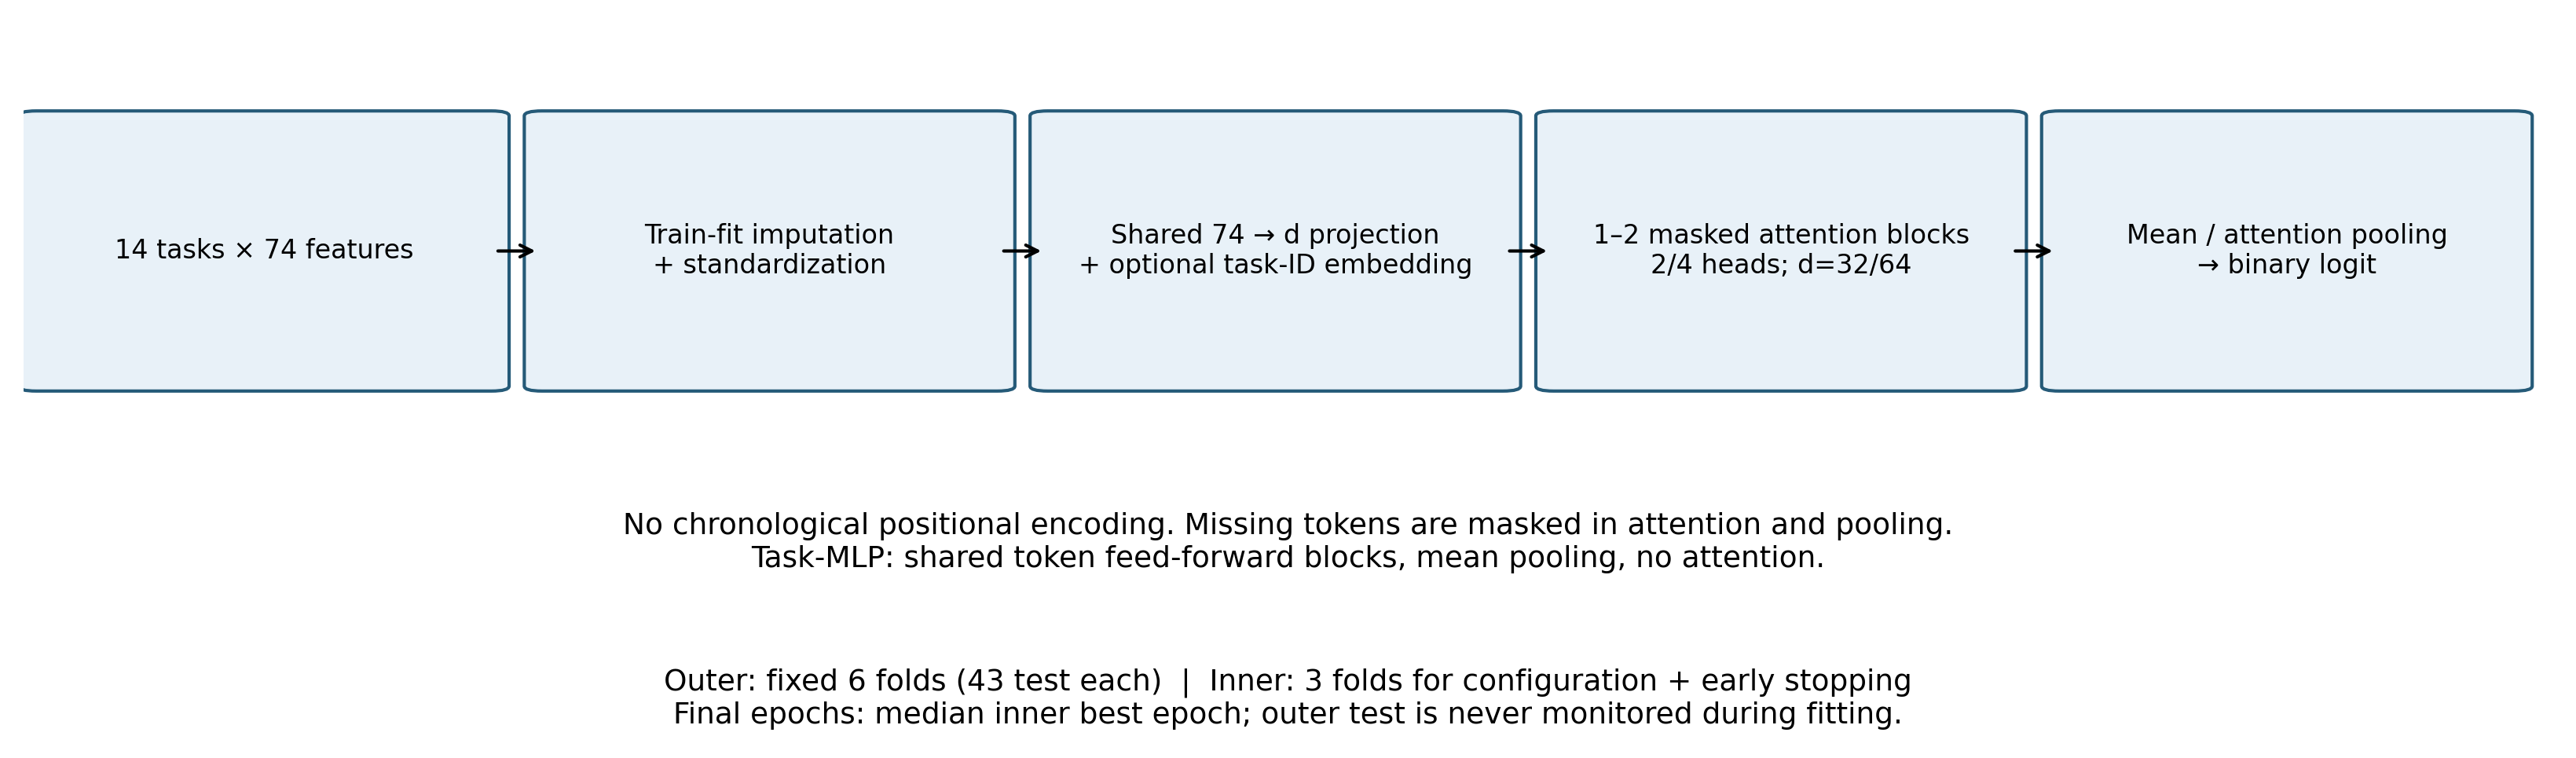

**02_predictive_ablation** — Fold meanÂ±SD and pooled OOF; no outer-test winner selection.

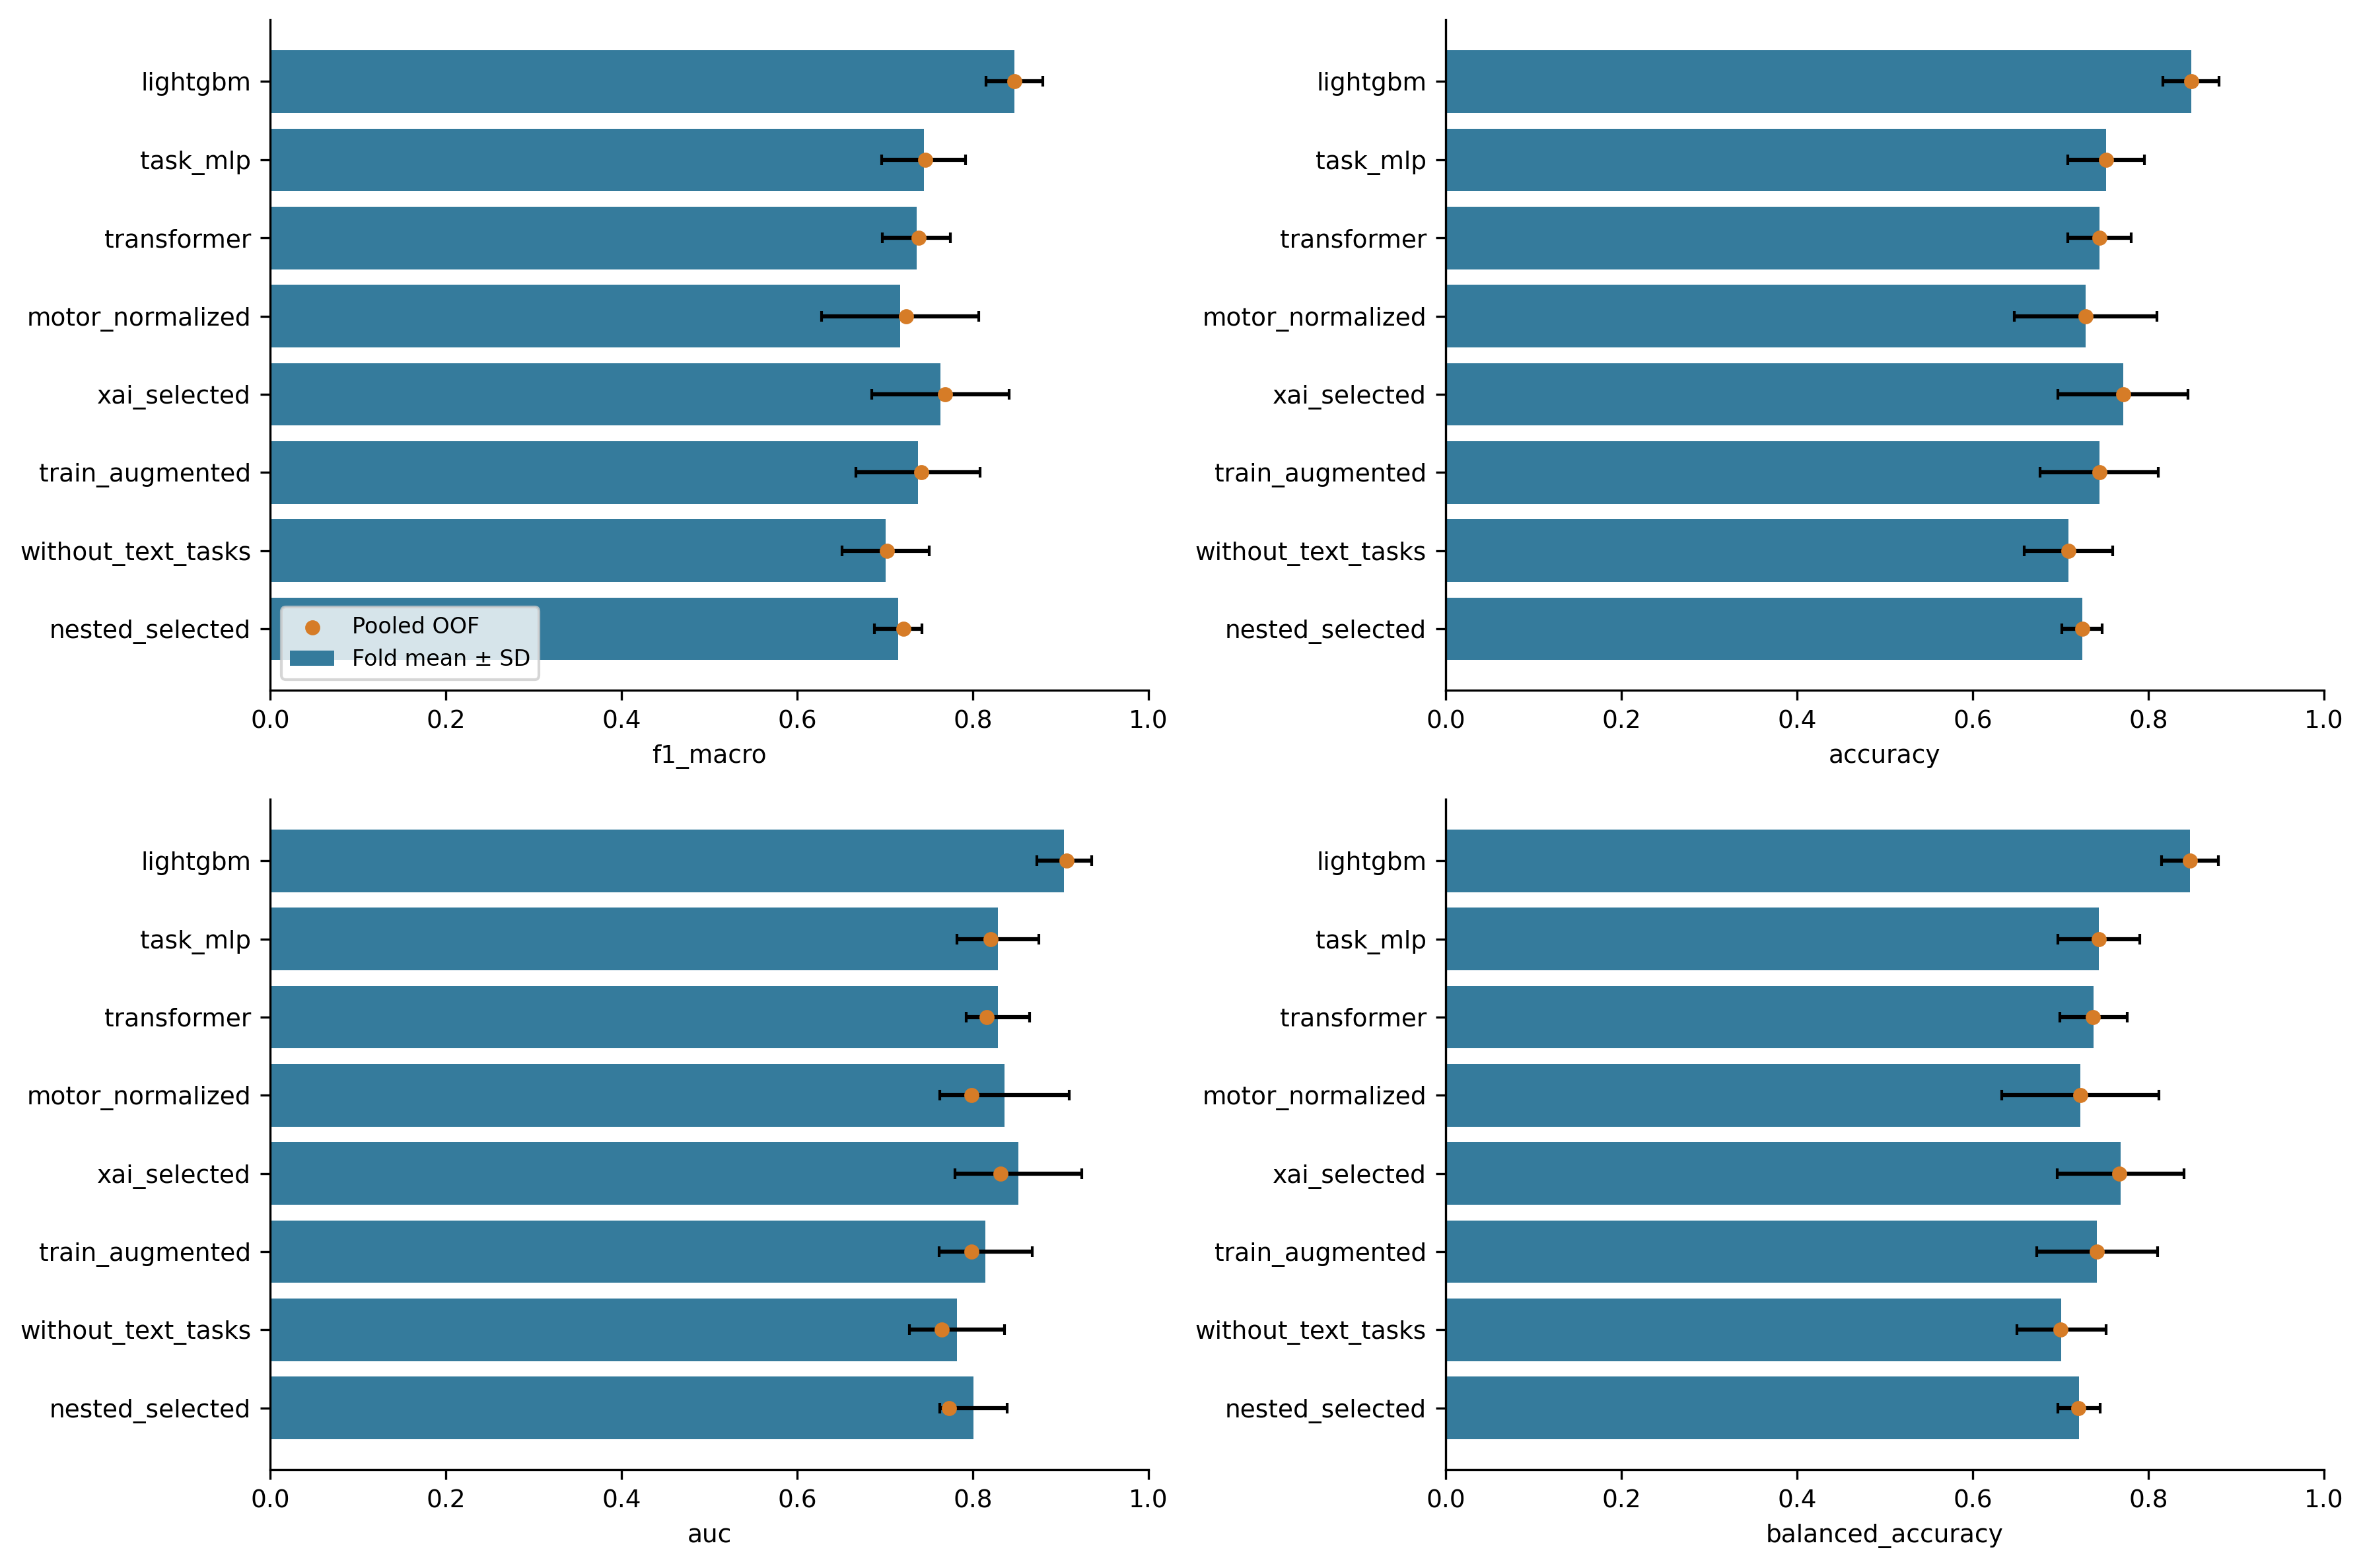

**03_matched_ablation** — Matched architecture controls; epochs selected independently in inner CV.

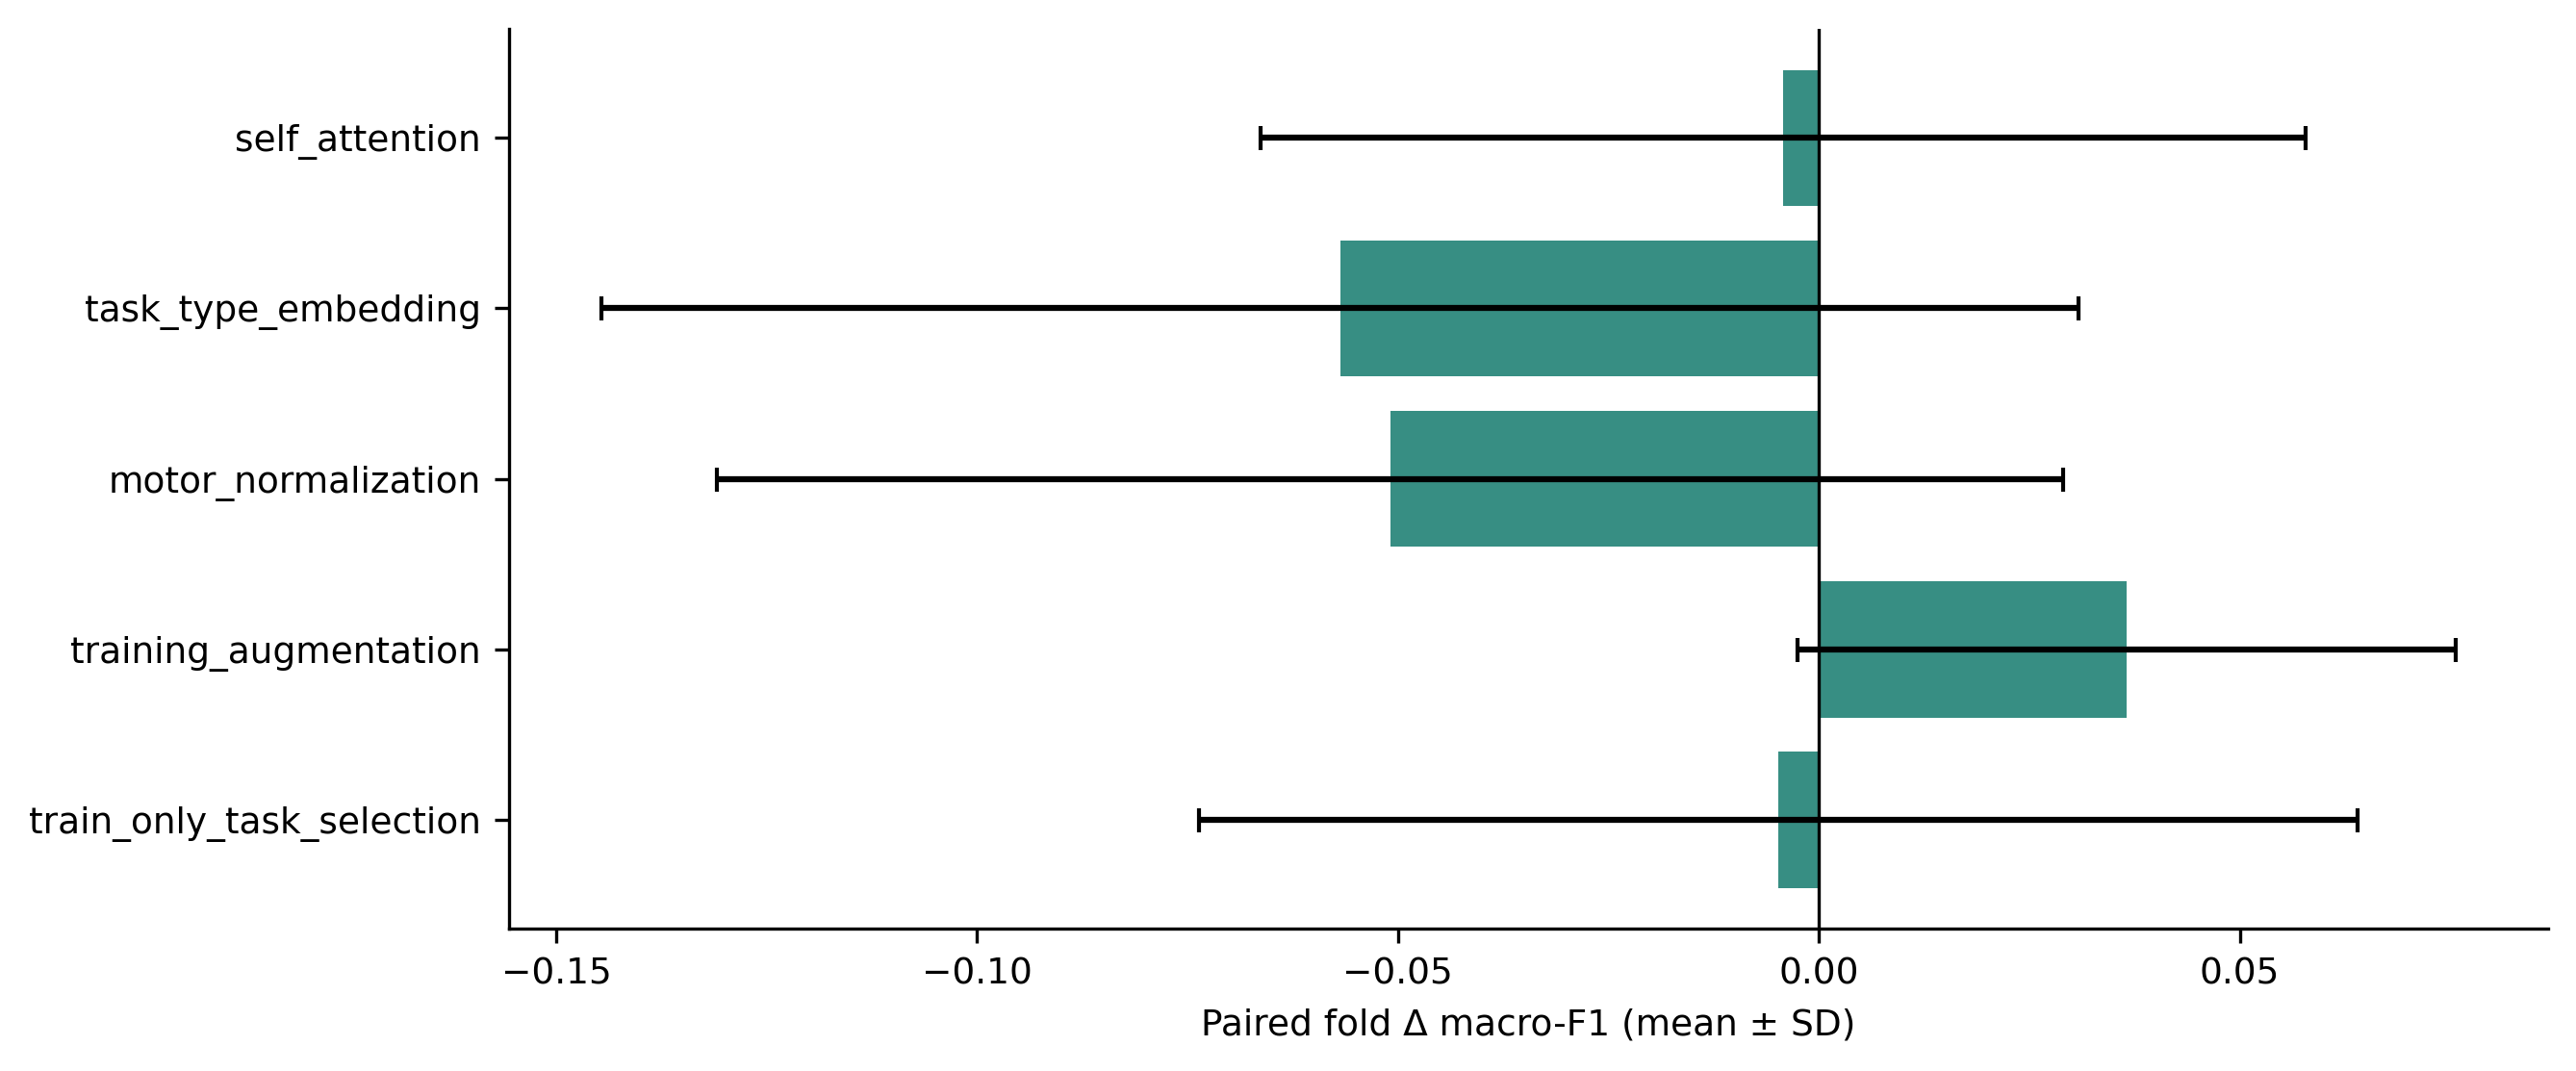

**04_seed_sensitivity** — Fixed selected configurations, three training seeds; same participants and splits.

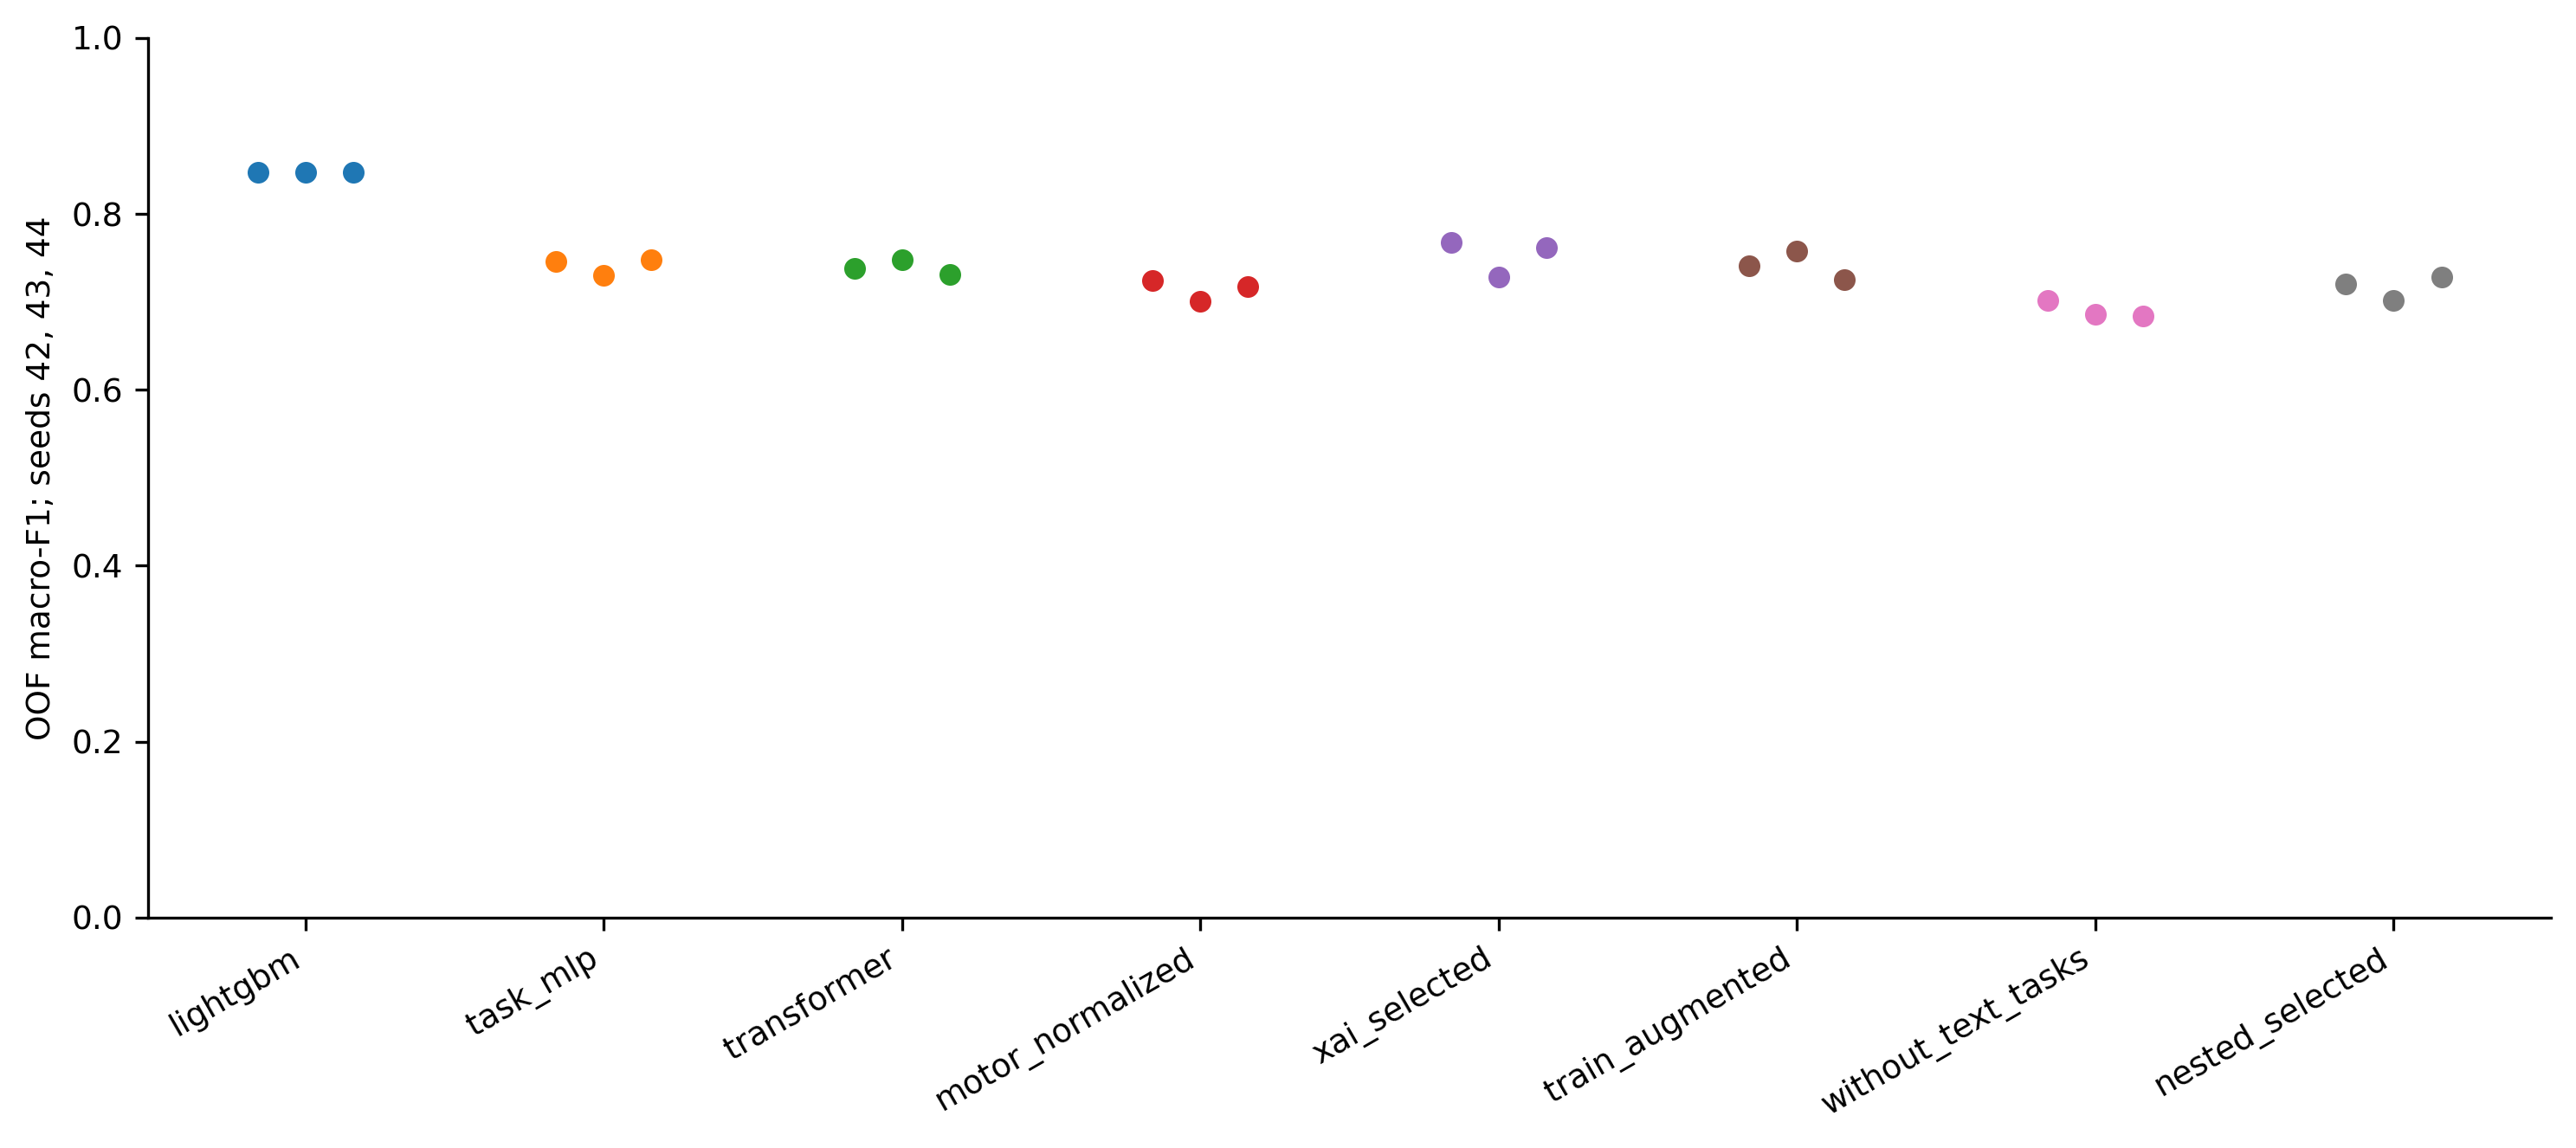

**05_learning_curves** — Descriptive mean over inner searches; later epochs contain fewer runs due to early stopping.

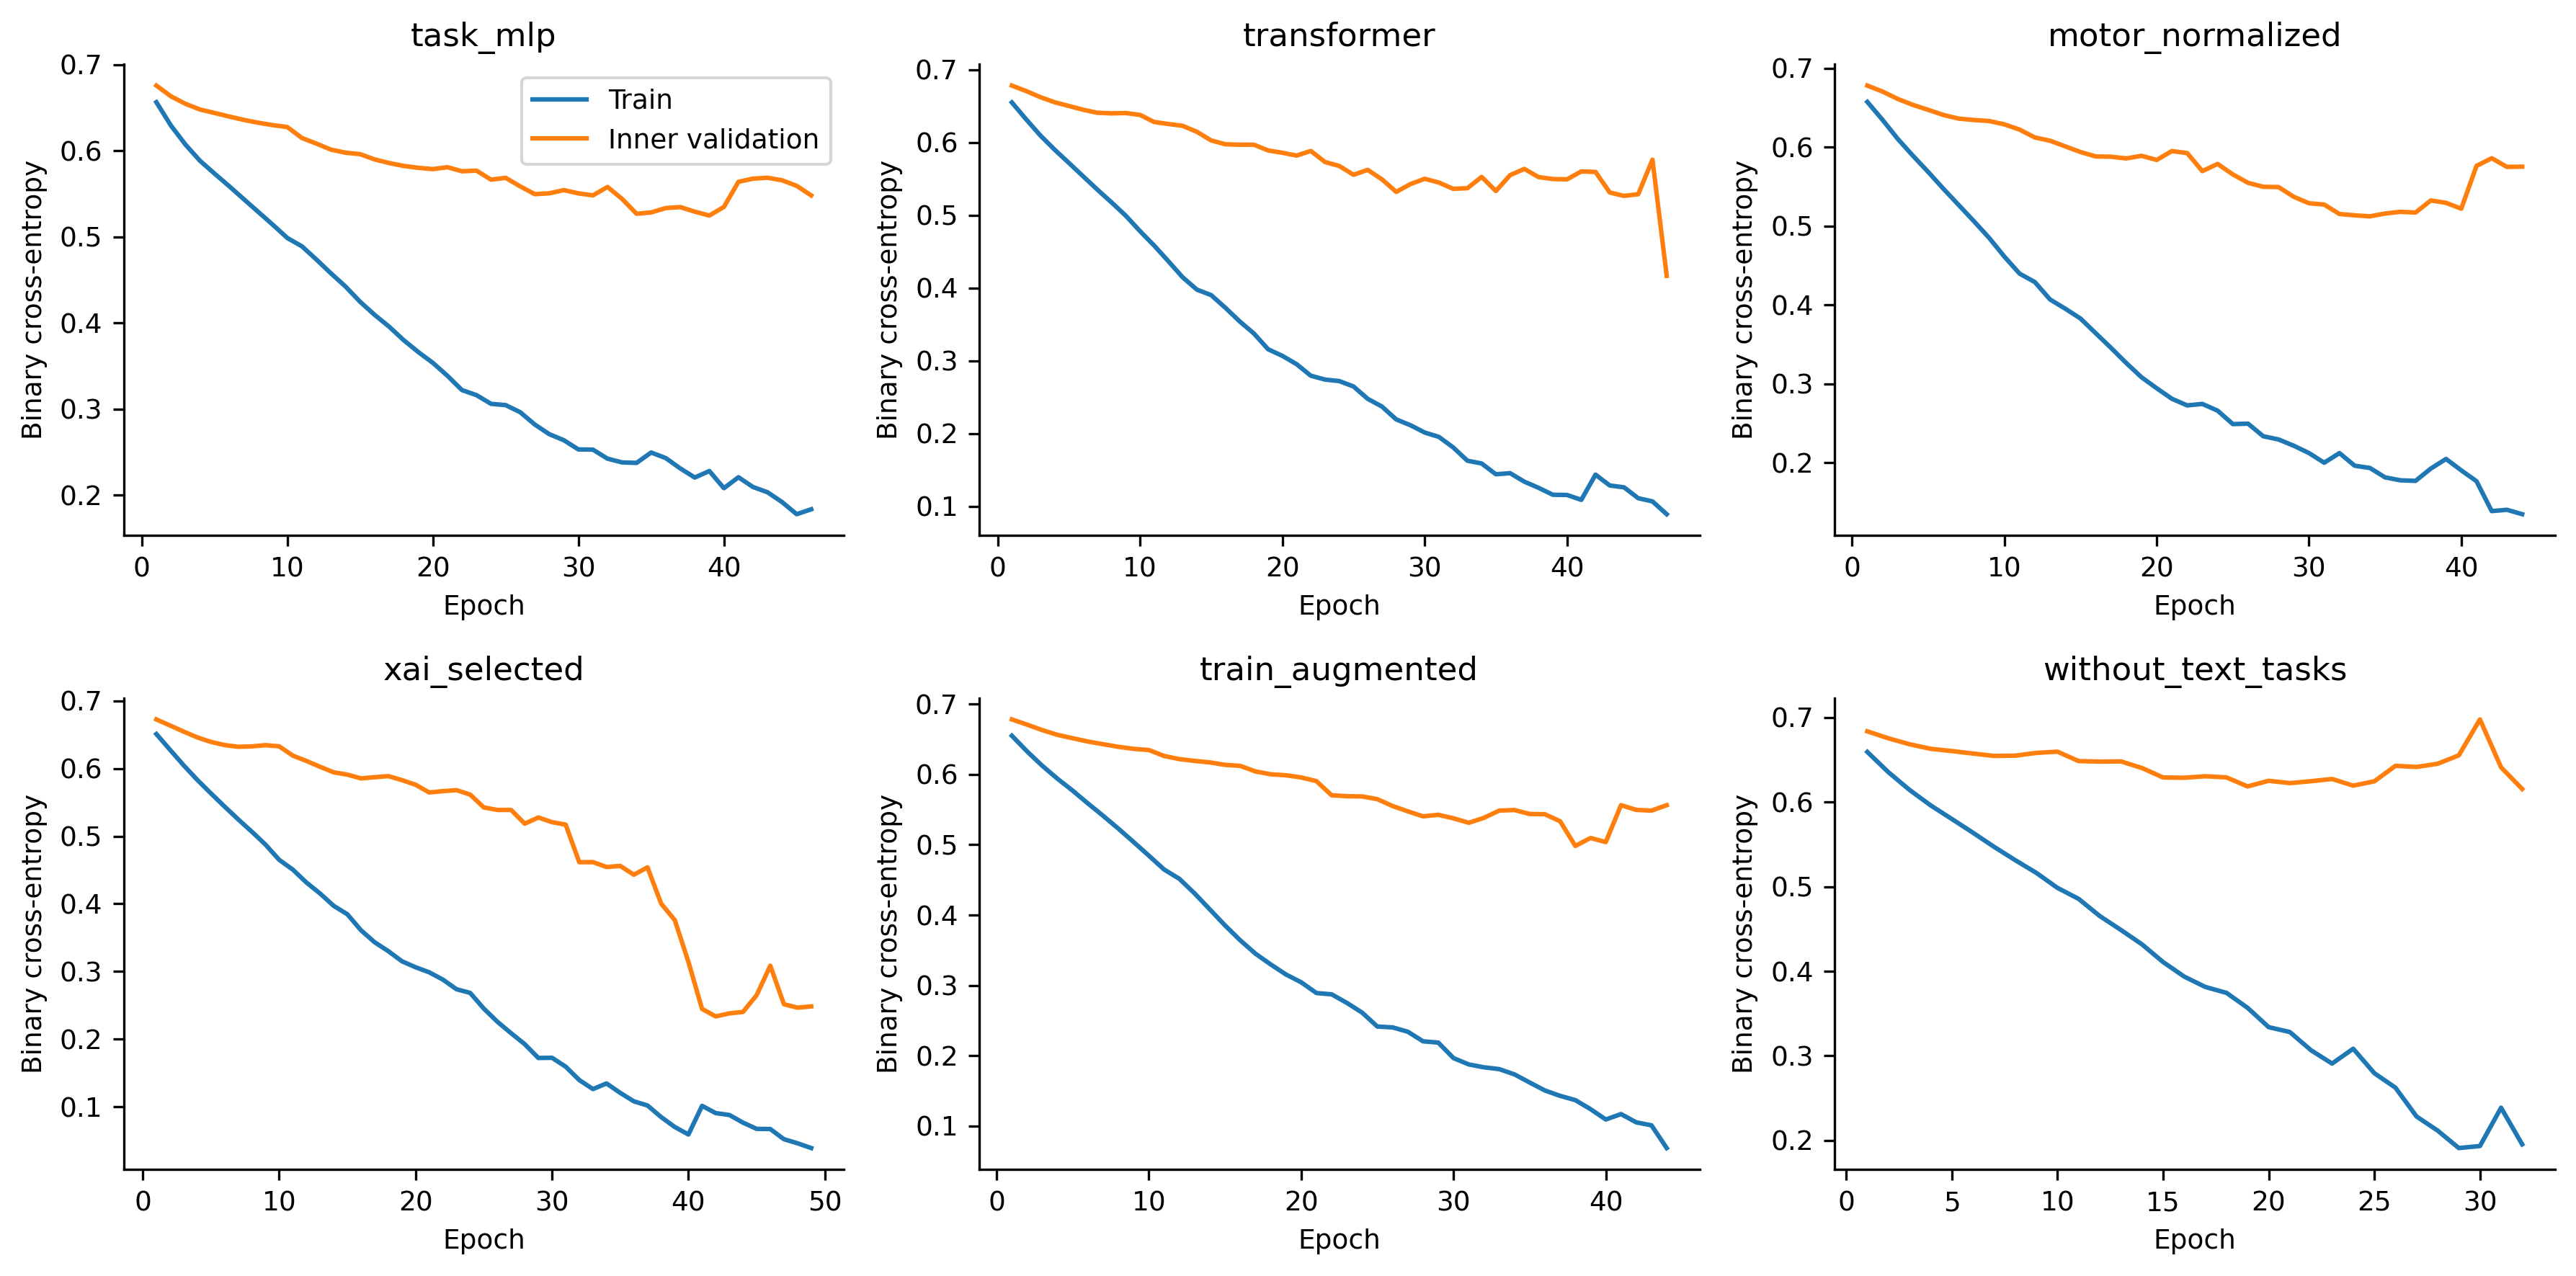

**06_compute_cost** — CPU LightGBM vs GPU neural timing includes preprocessing and transfer; excludes raw extraction; hardware differs.

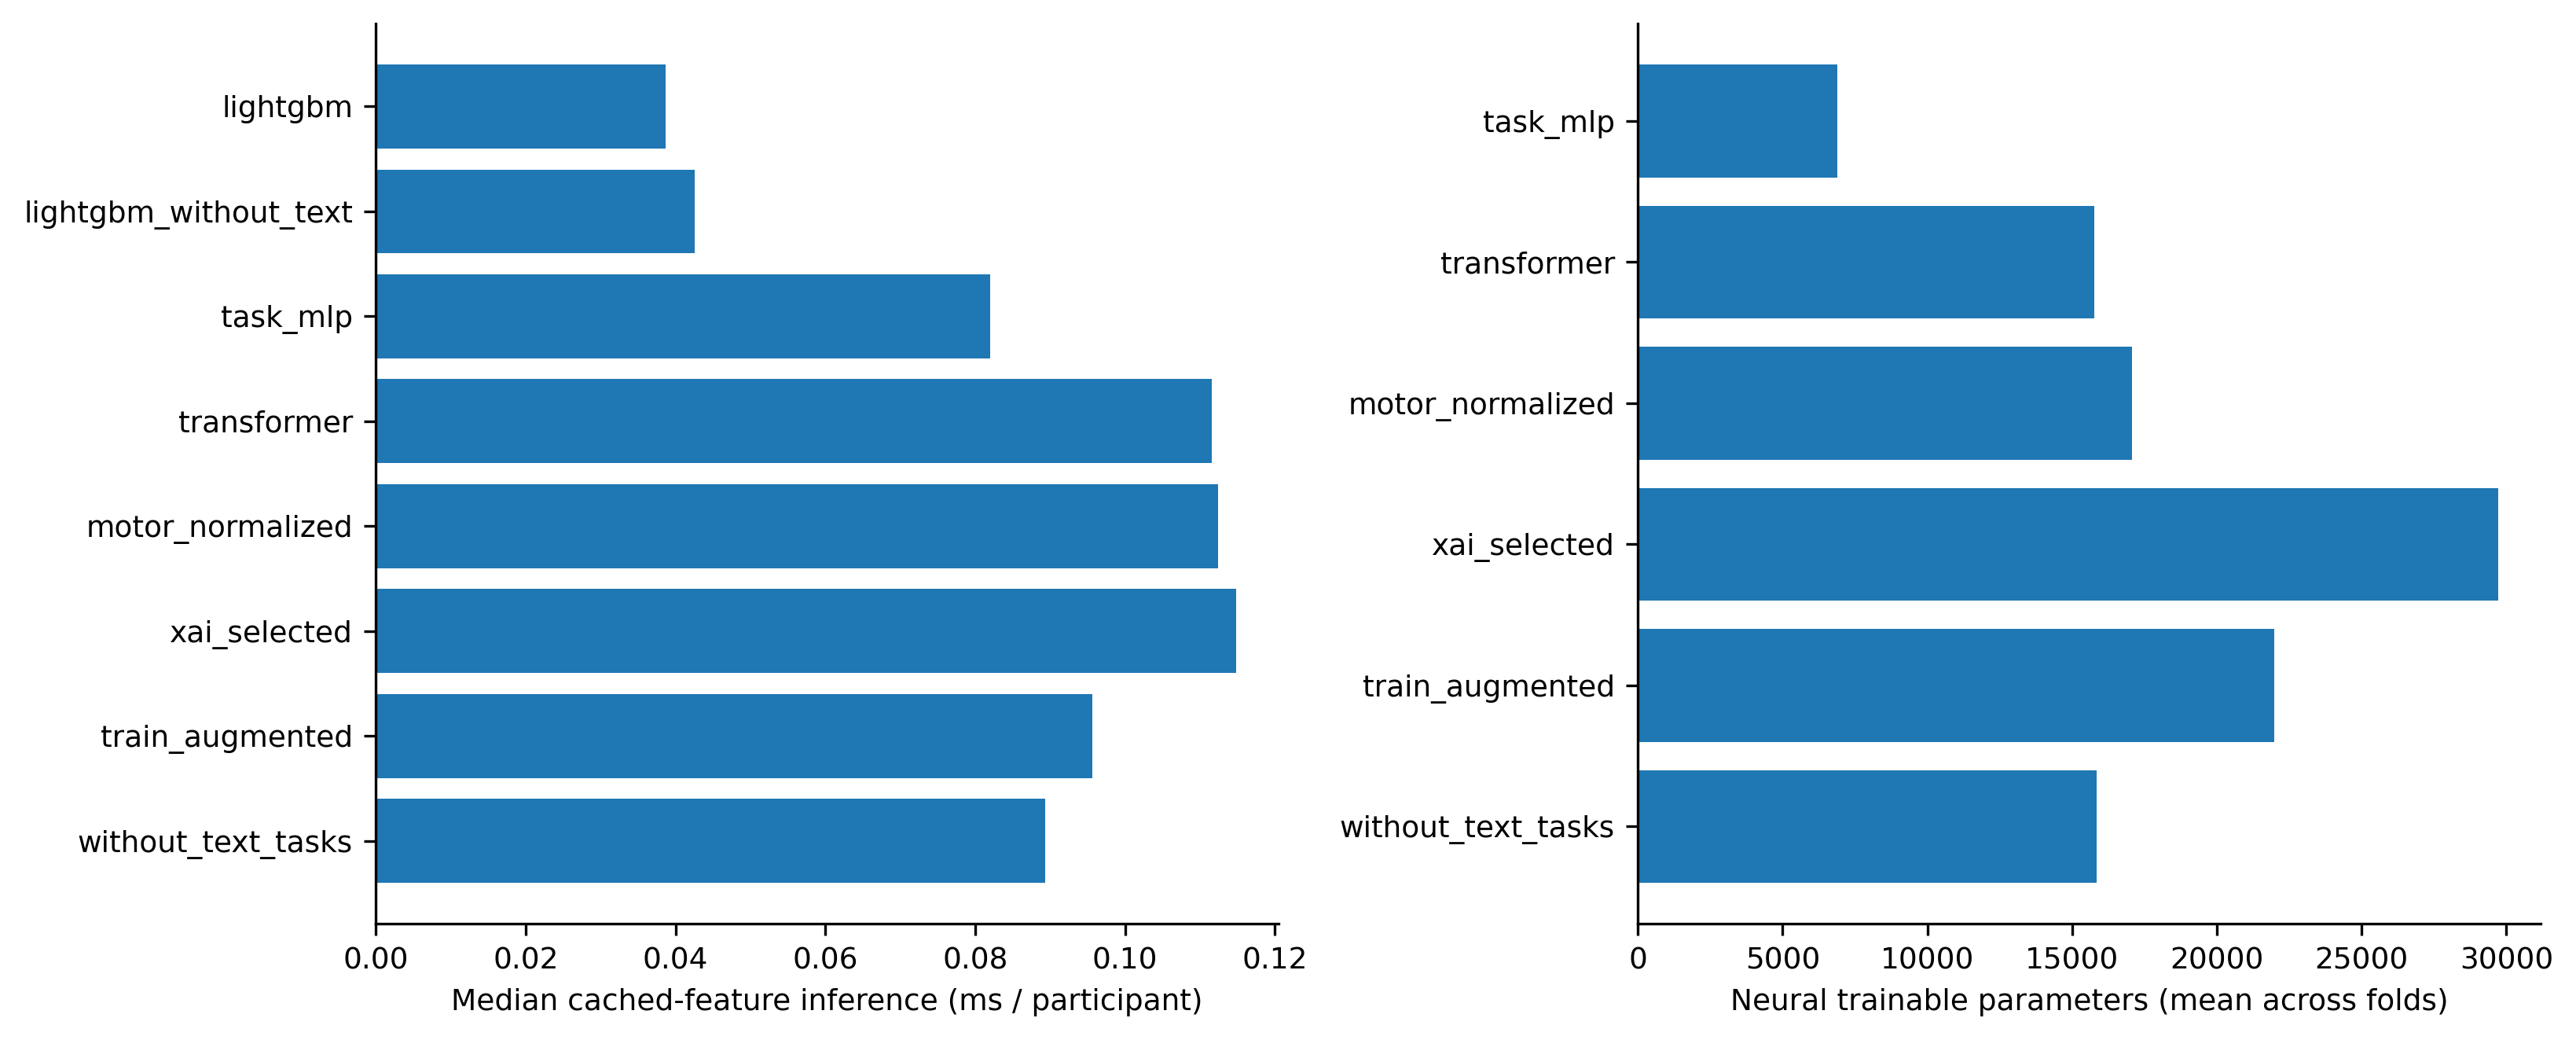

**07_nuisance_robustness** — Fixed post-fit raw-signal stresses, not external device or language validation.

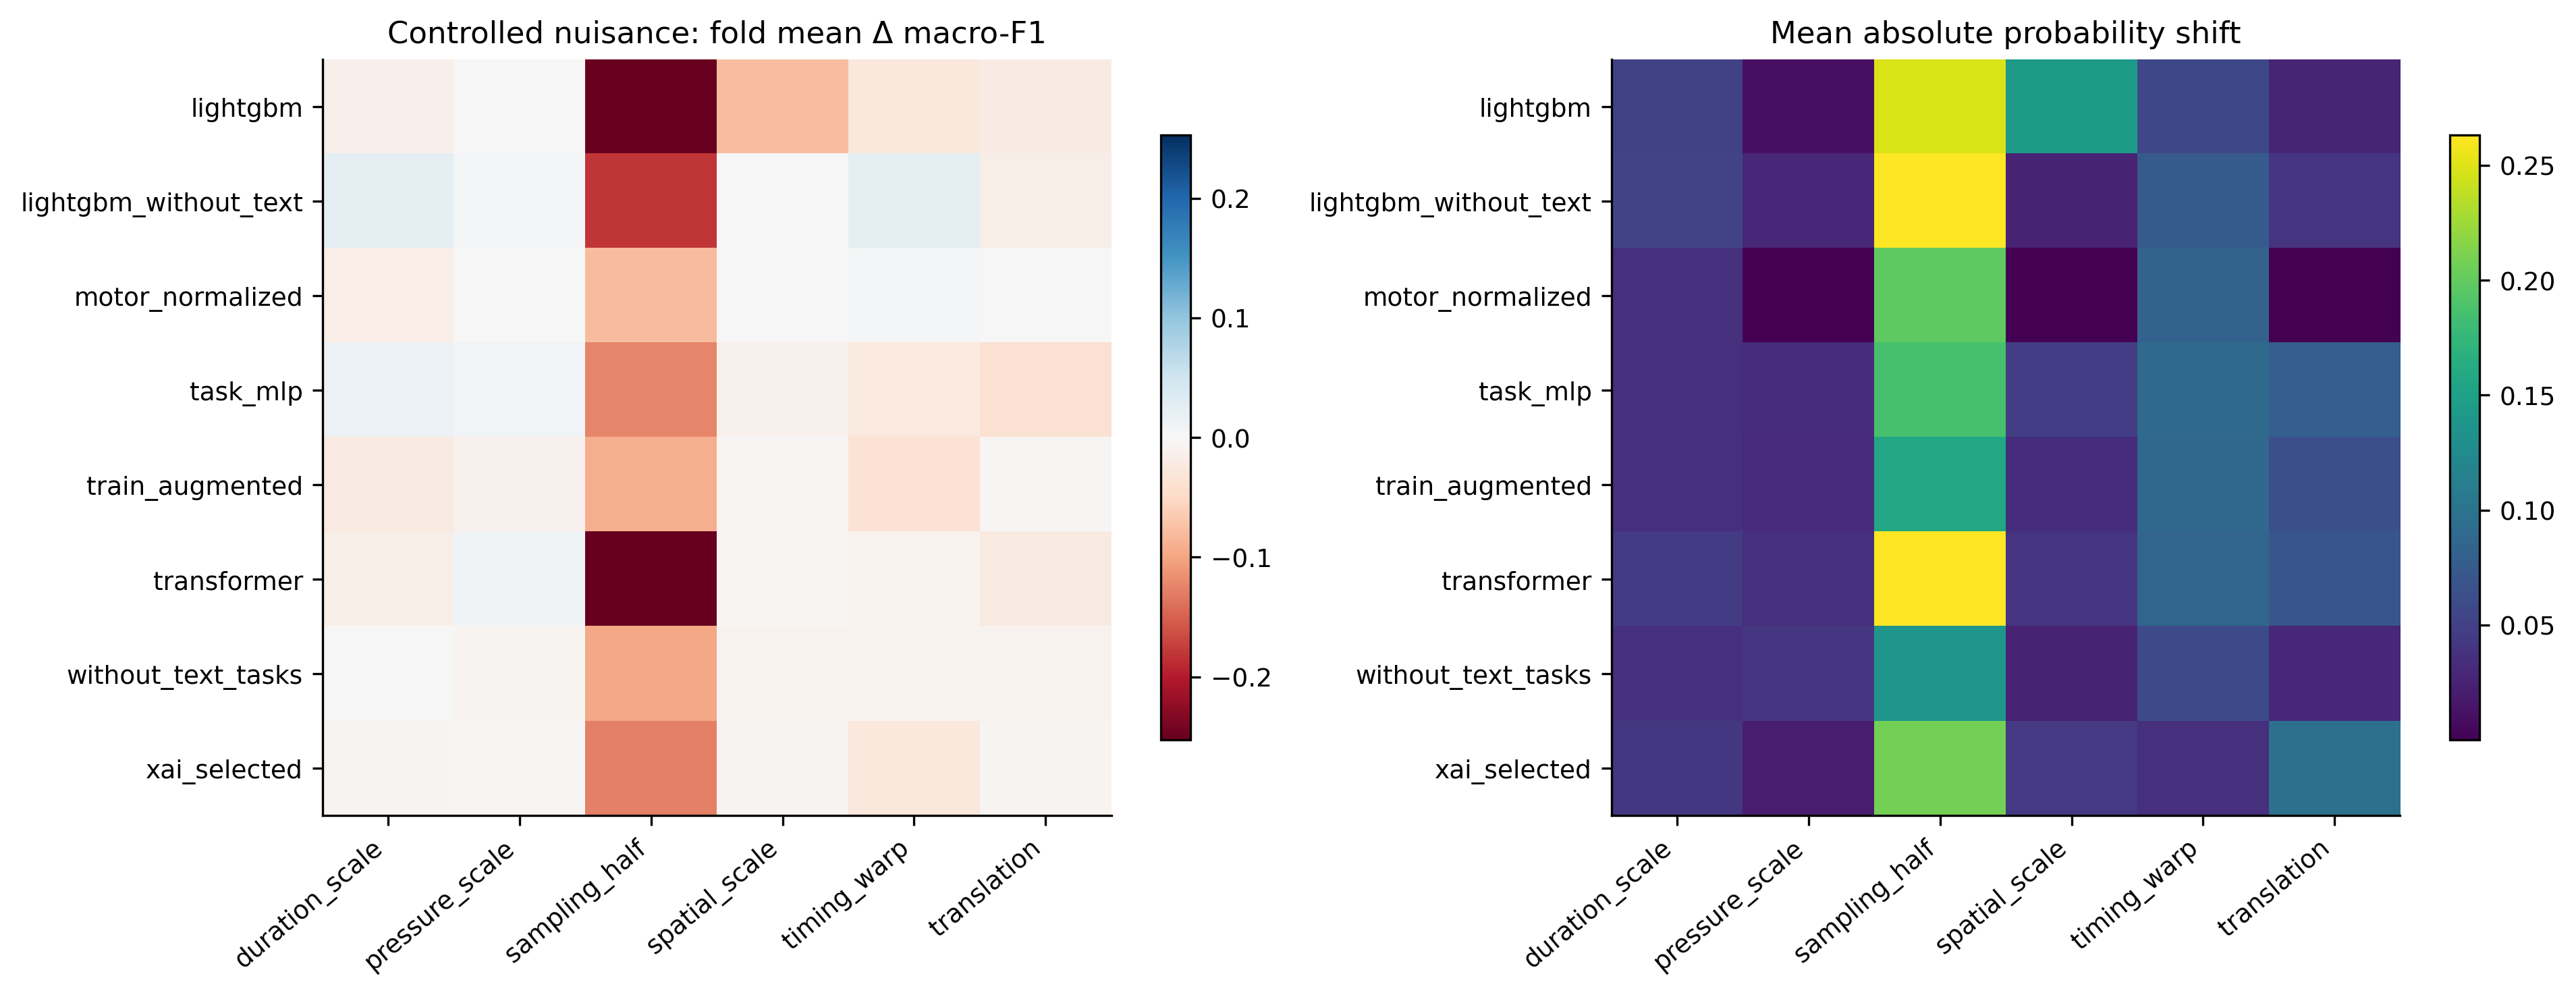

**08_missing_tasks** — Native neural token masks; tree Train-median replacement; draws averaged within each fold.

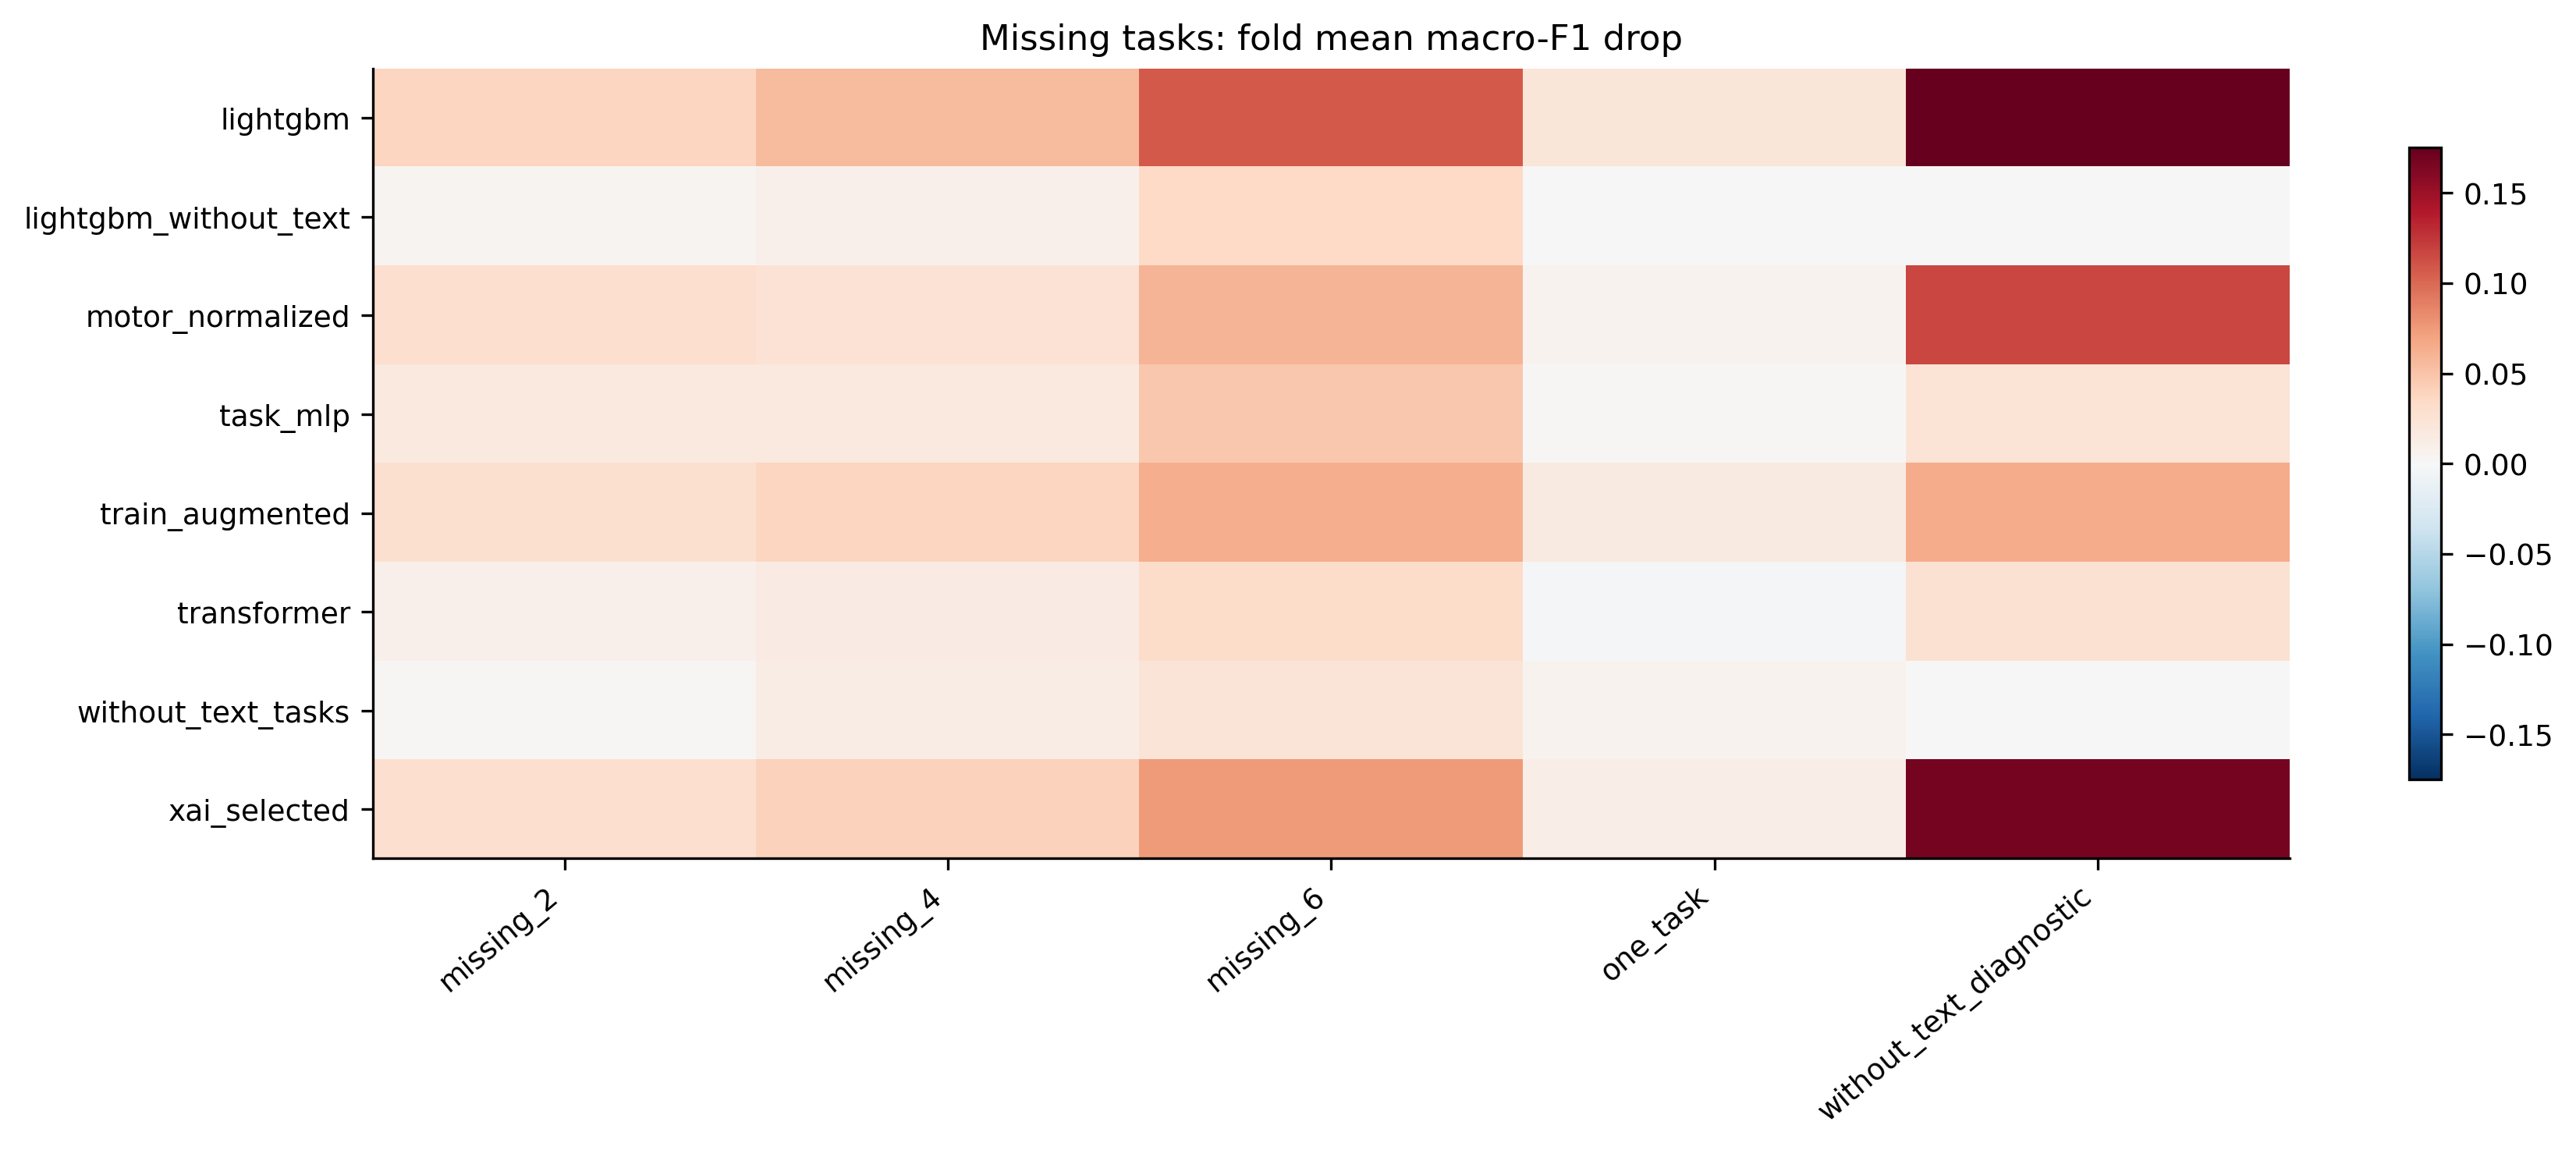

**09_attribution_patterns** — Absolute held-out IG / SHAP mass shares; different references; no causal interpretation.

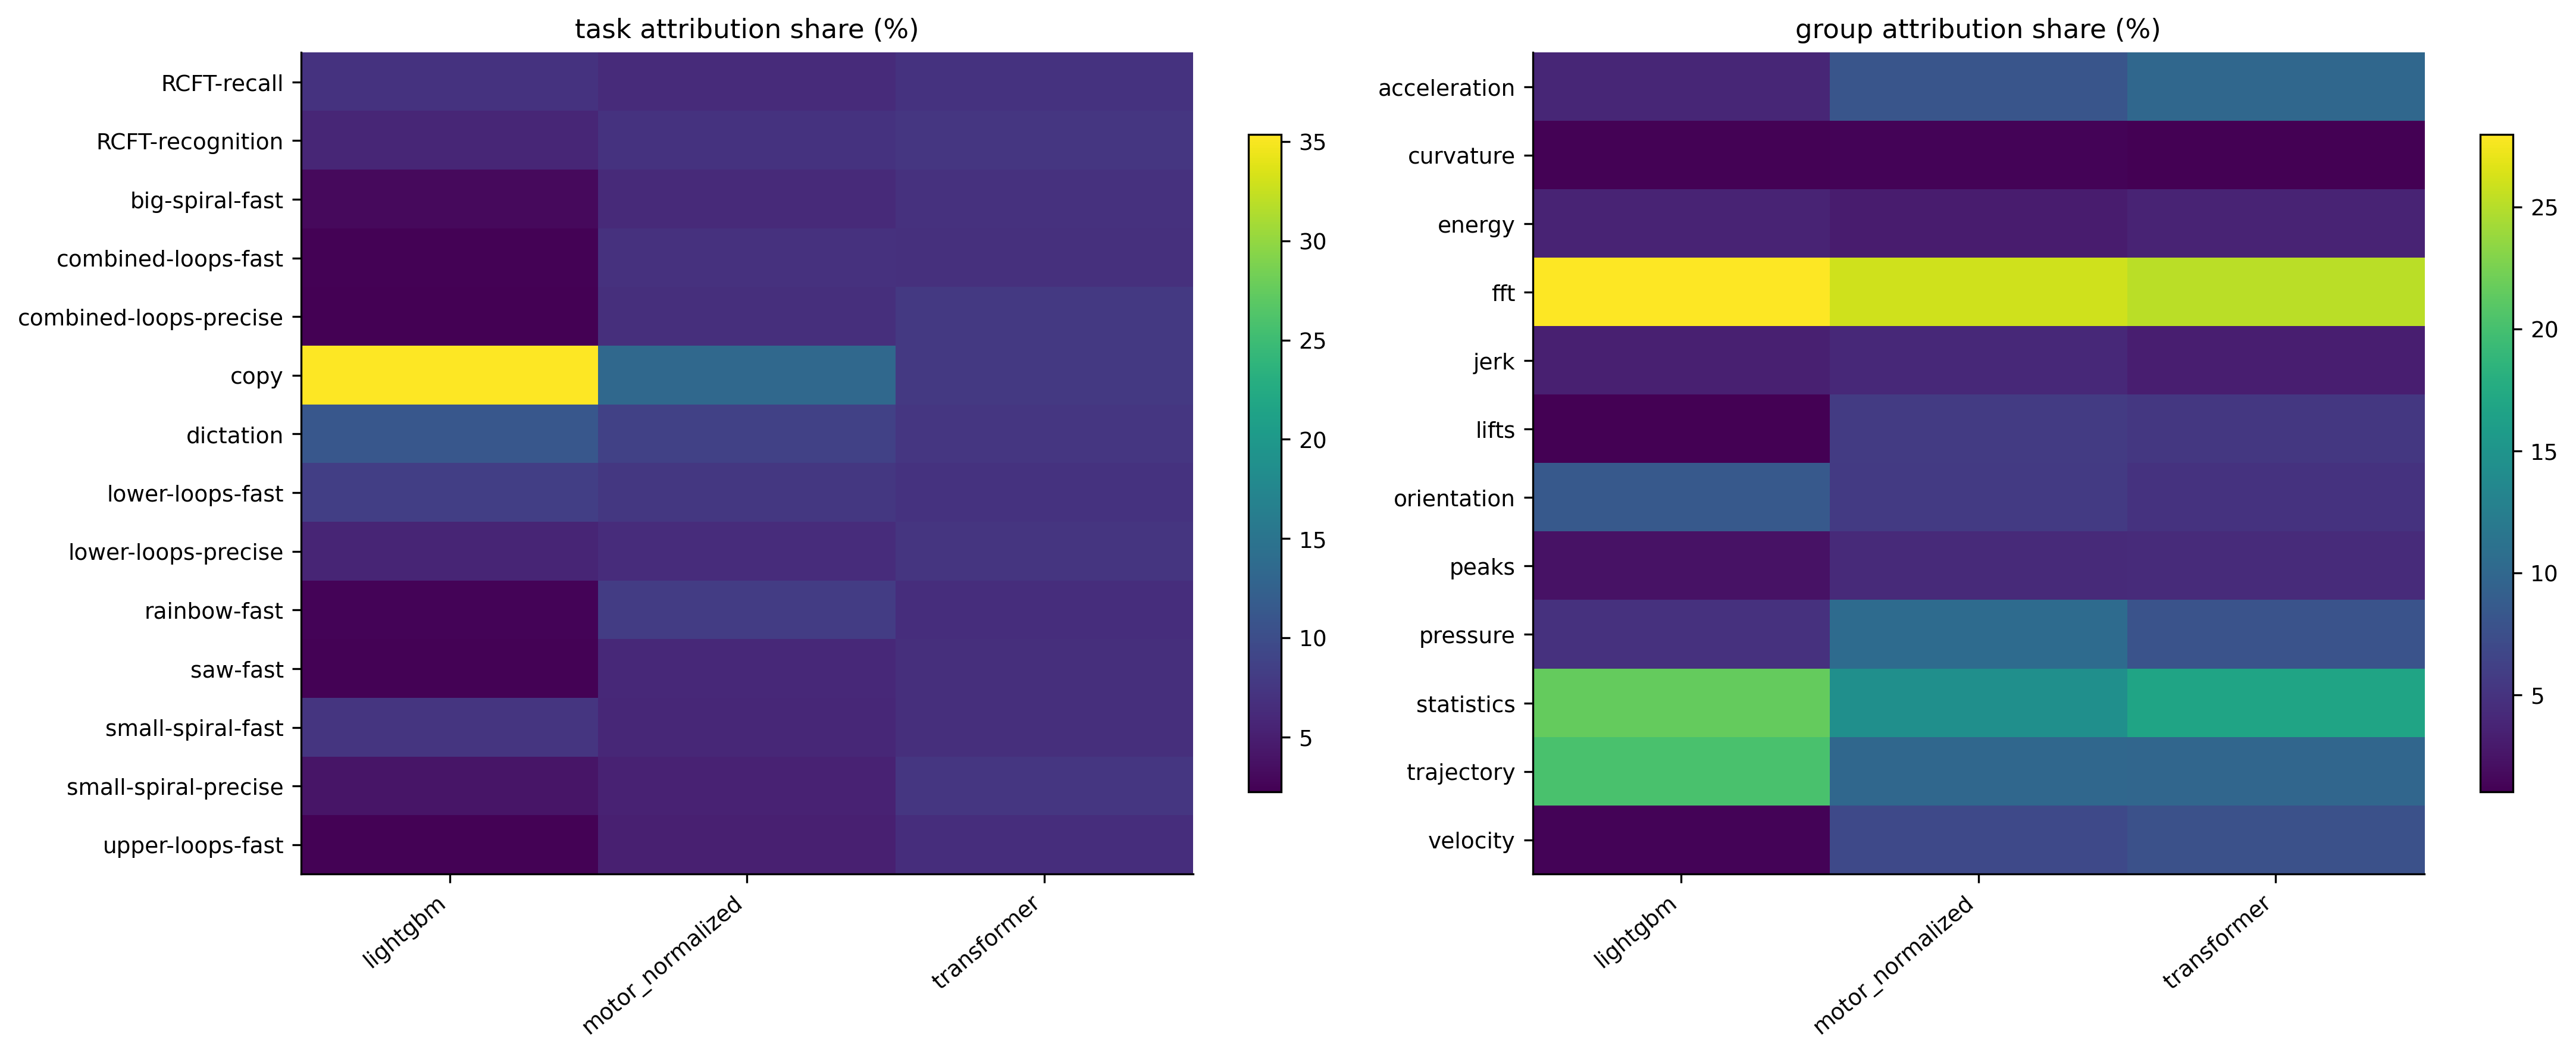

**10_attribution_stability** — Fold pairs are dependent; descriptive SD, not inferential evidence.

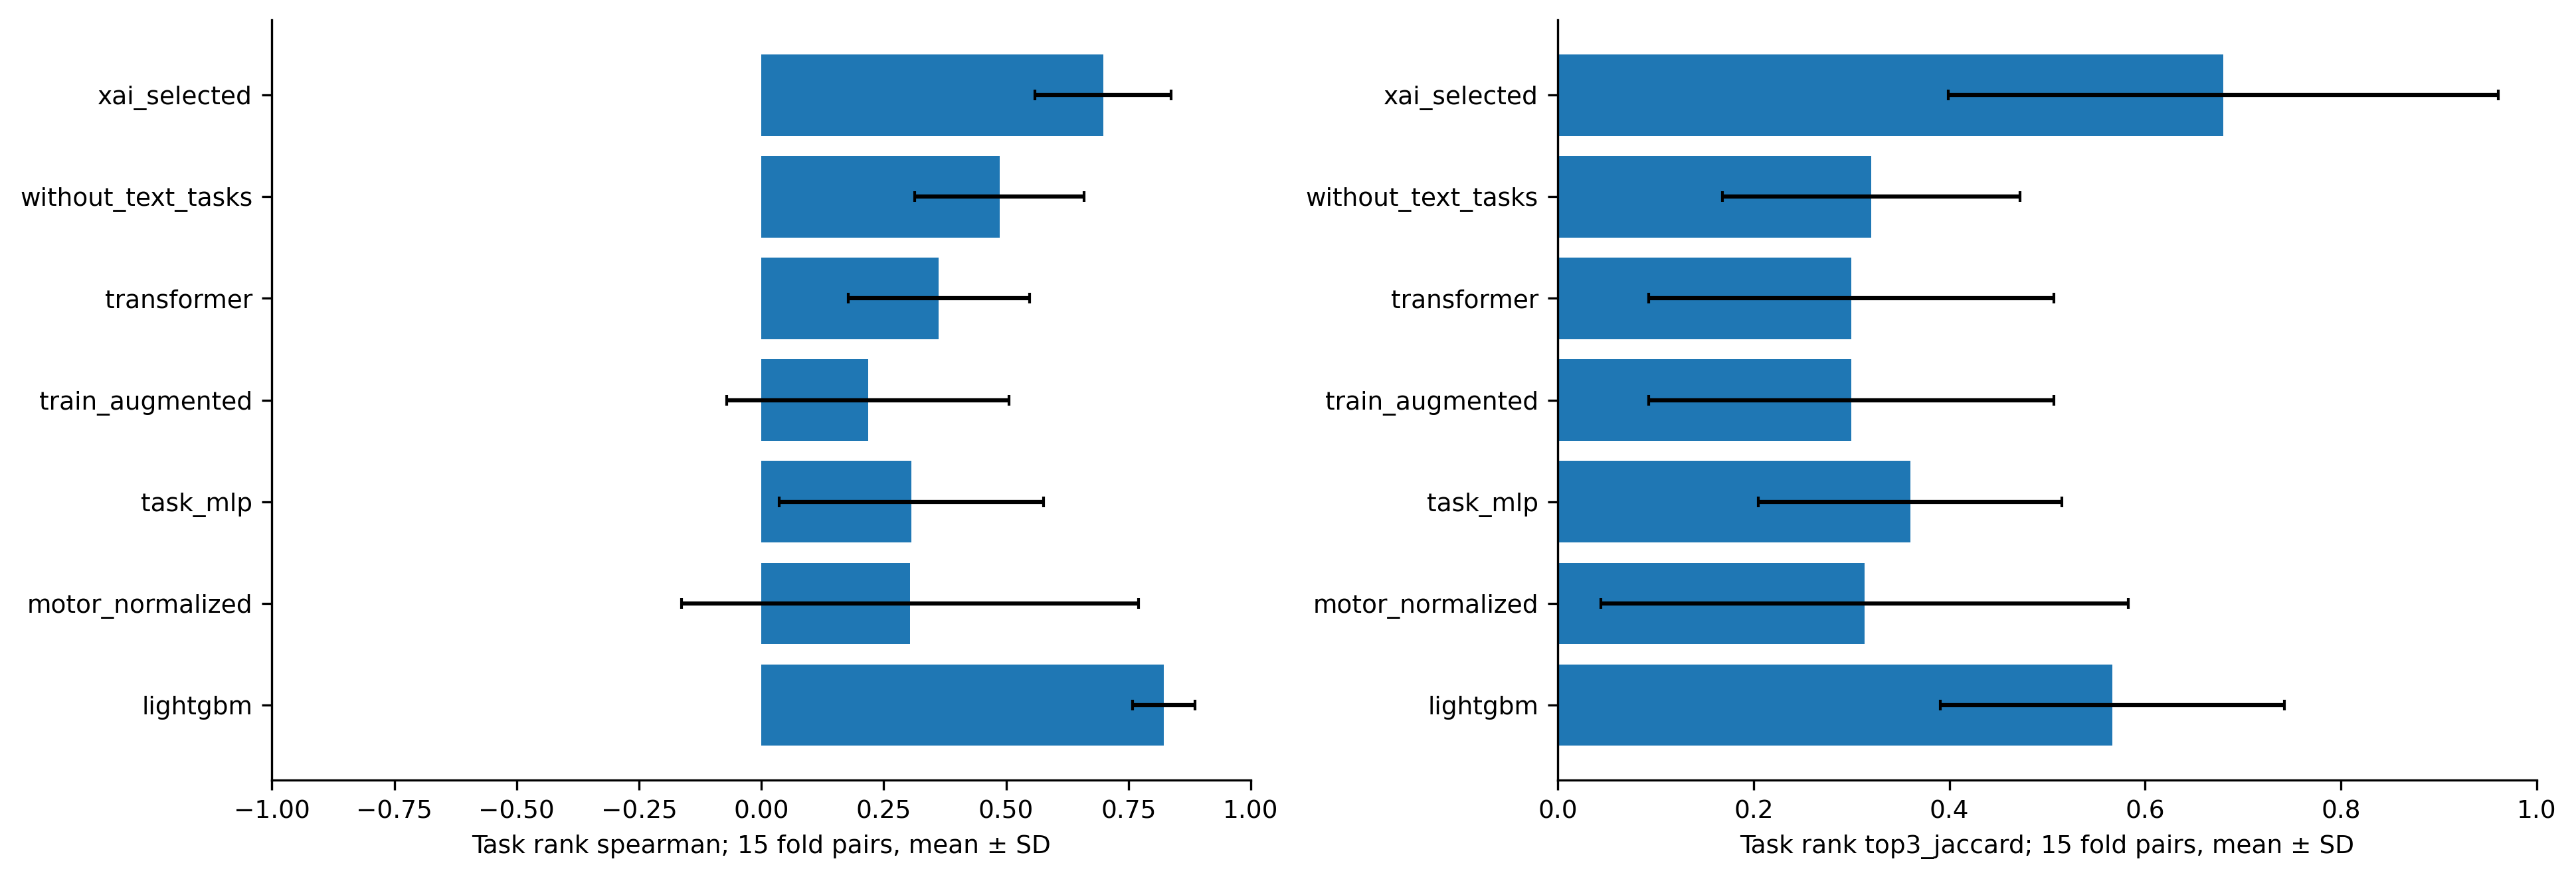

**11_faithfulness** — Permutation and zero-feature ablation are independent checks; correlations do not prove causal validity.

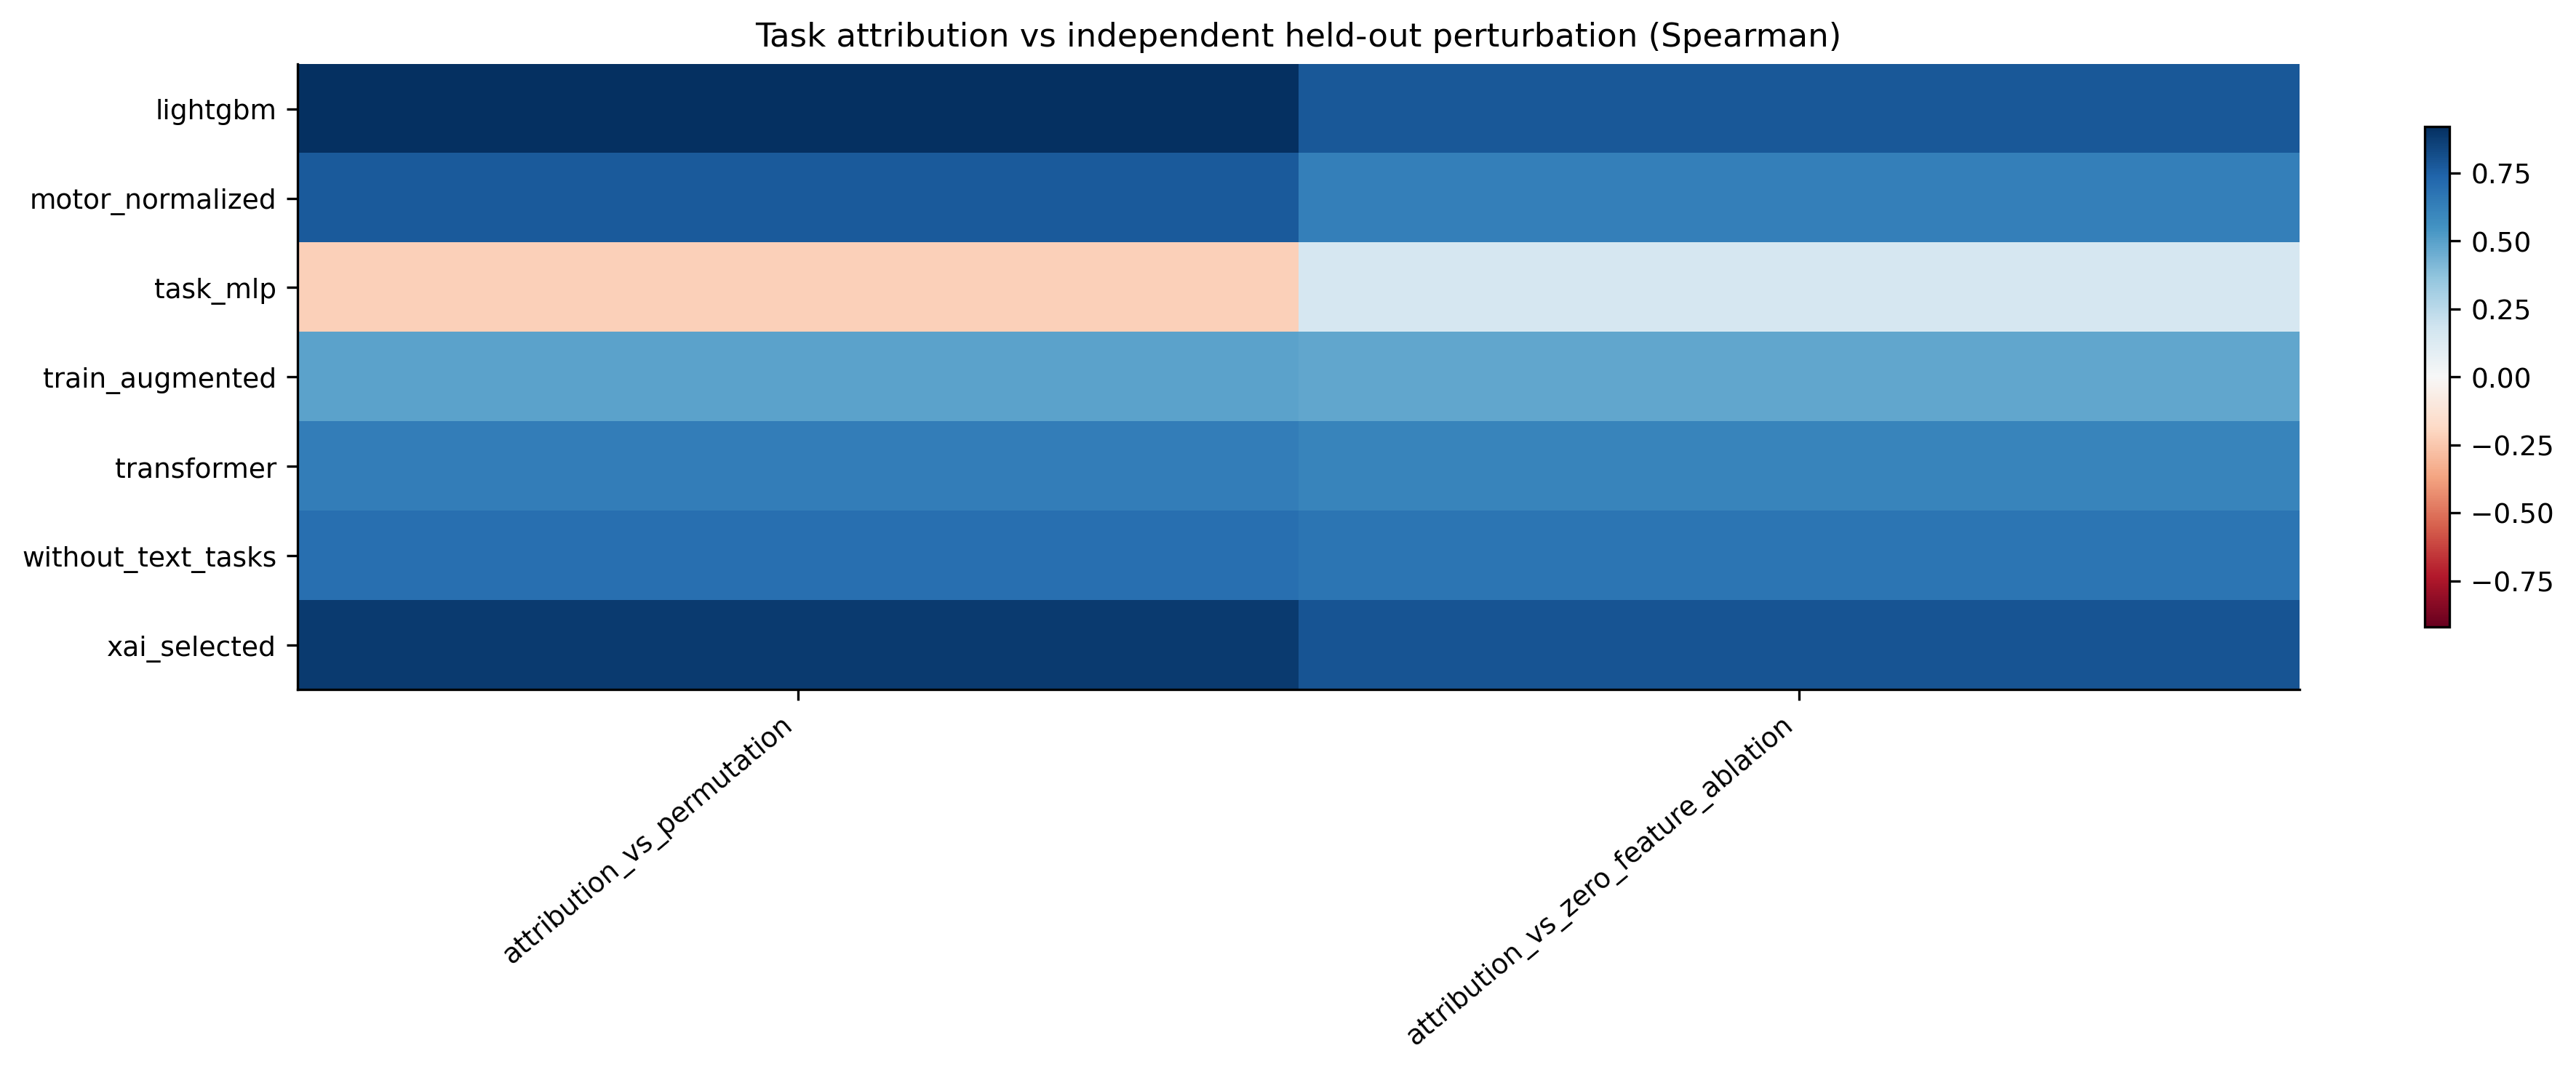

**12_attention_supplementary** — Mean incoming layer/head attention; model-specific missing tokens have zero weight.

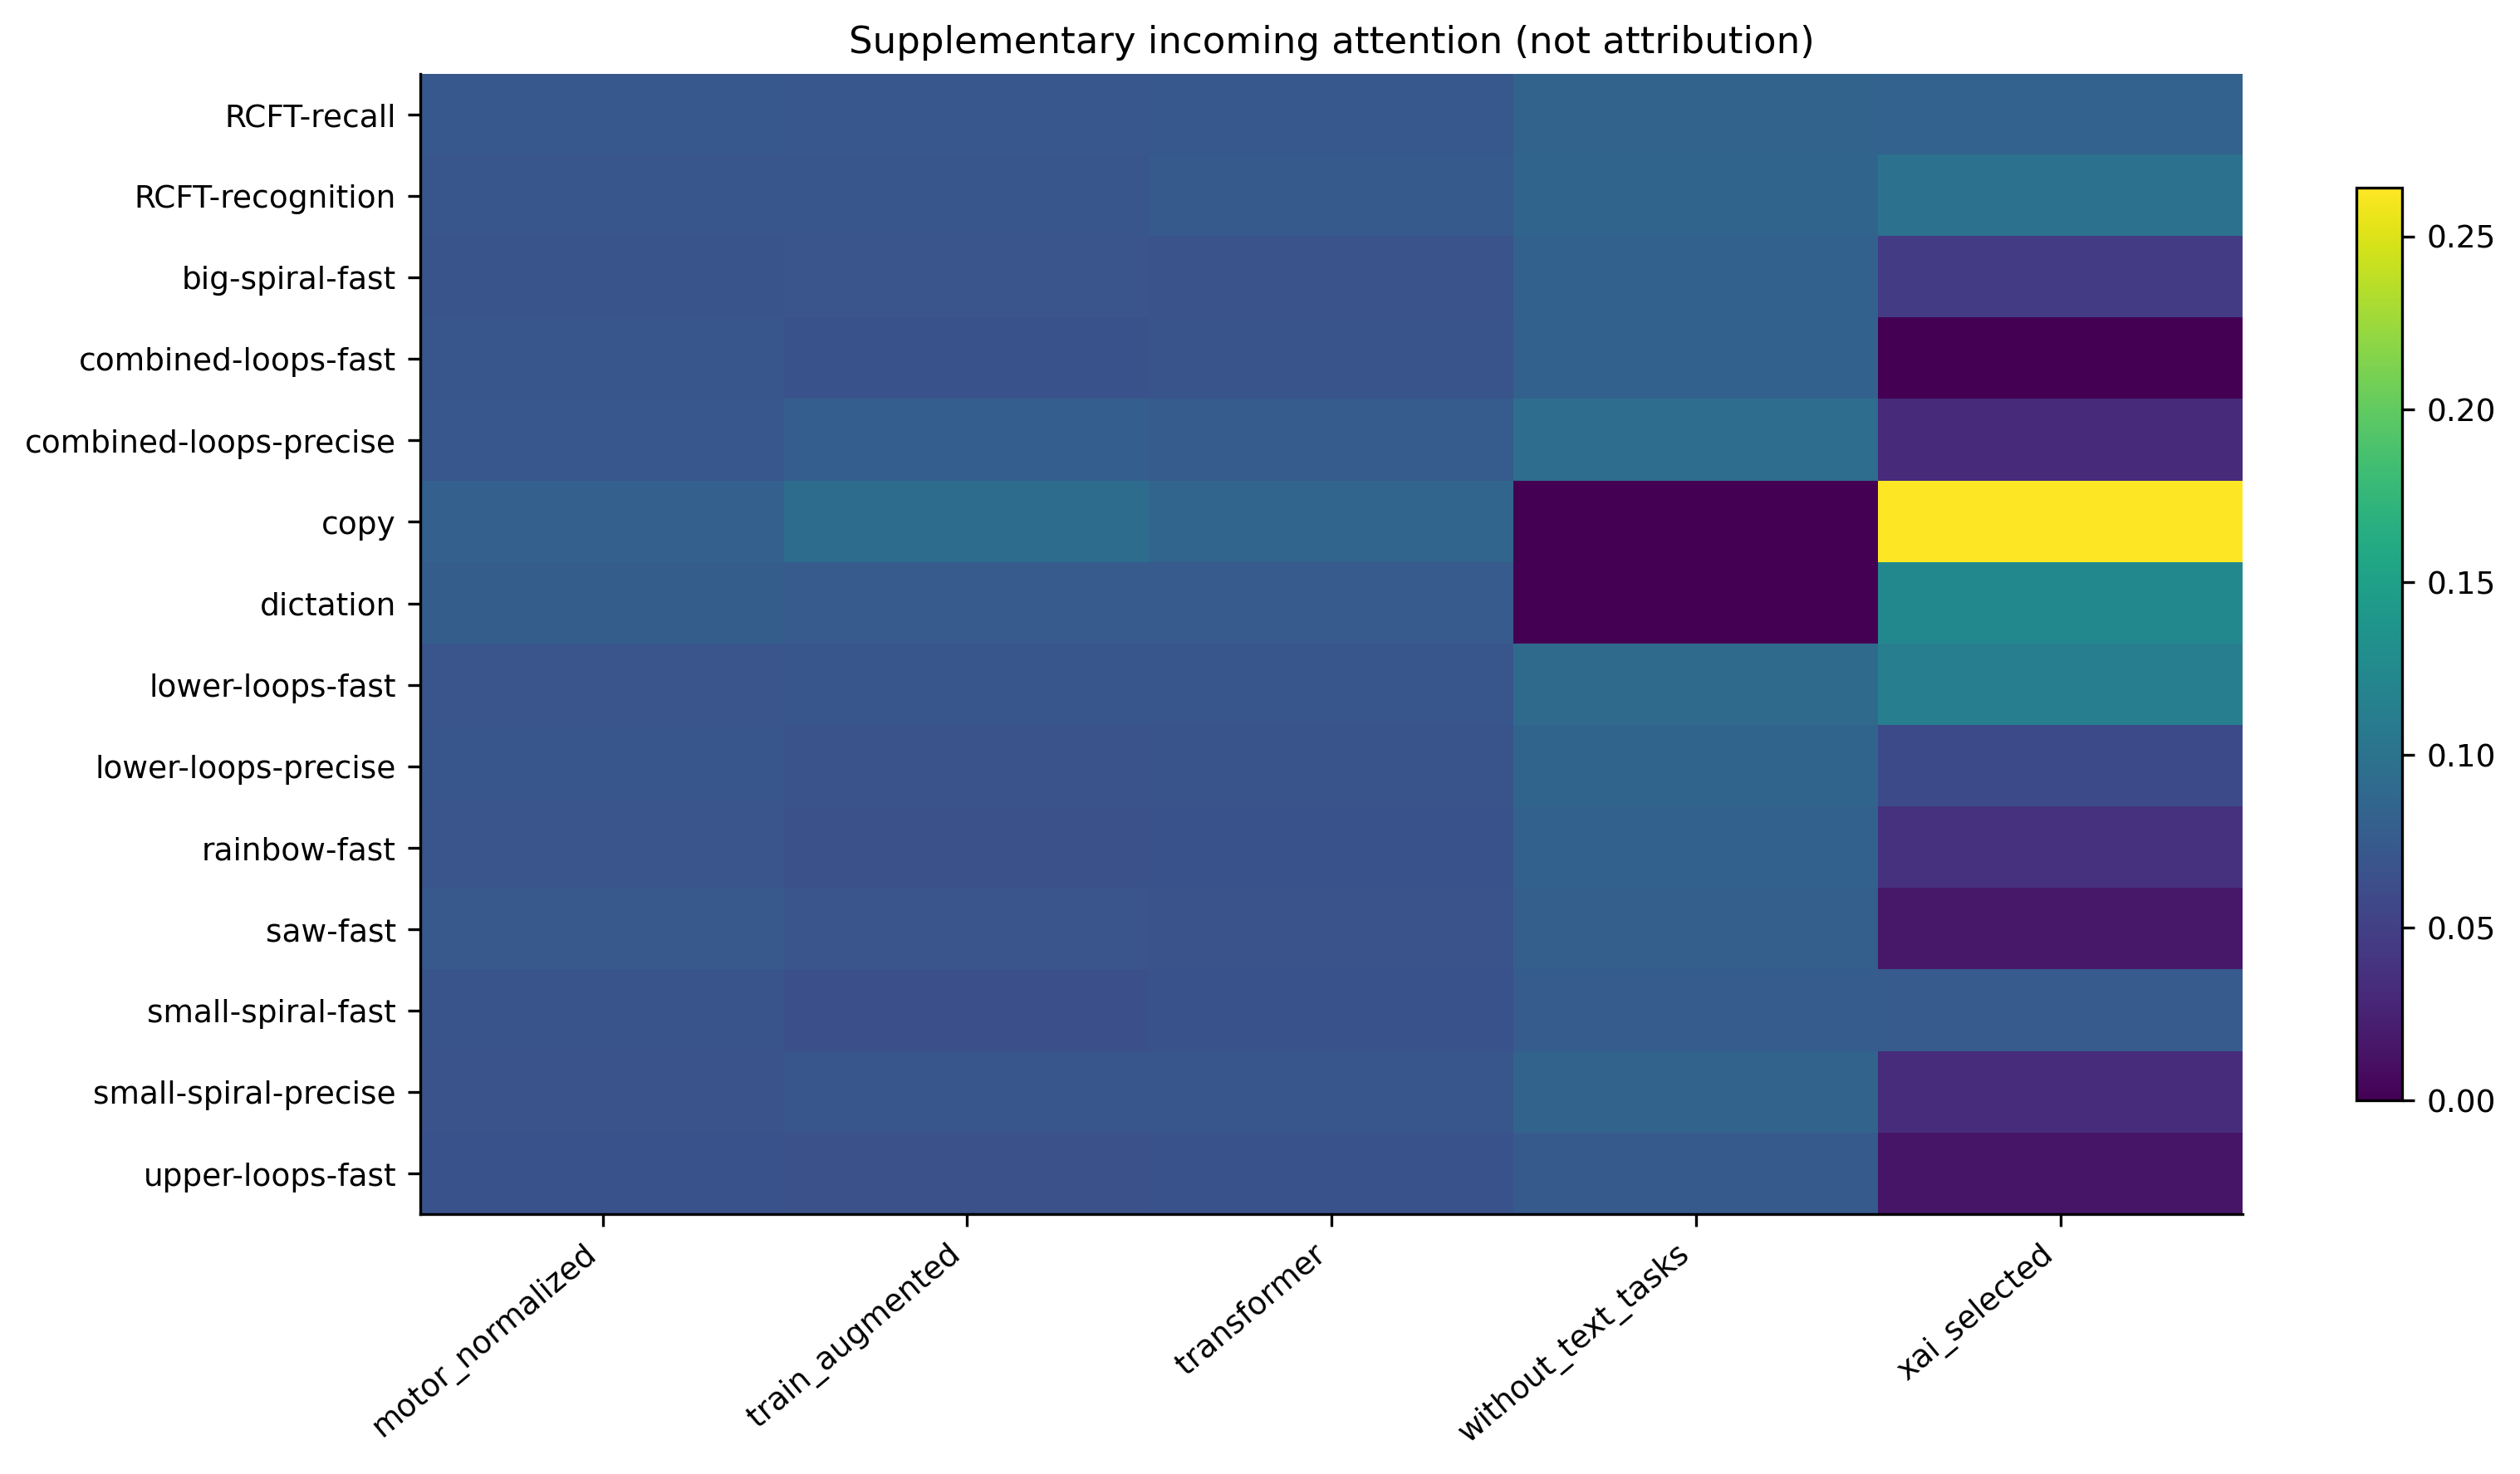

**13_confusion_matrices** — Seed 42 pooled OOF counts, each participant predicted once.

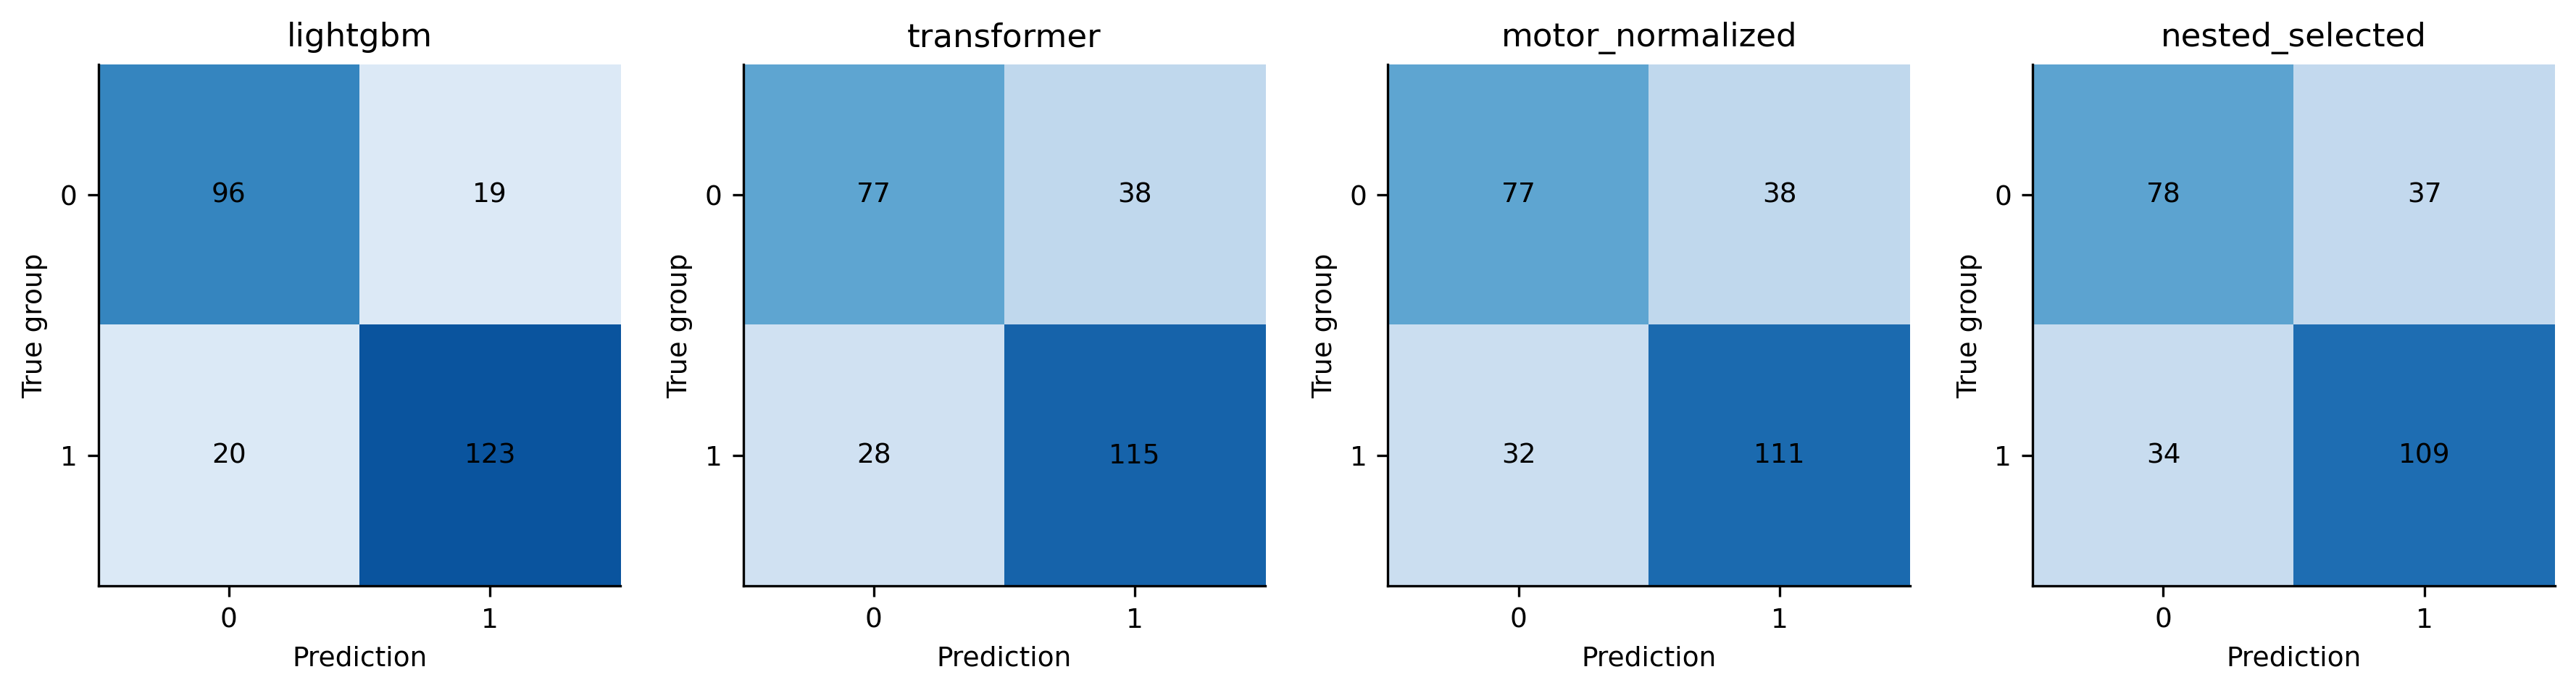

**14_paired_outcomes** — Same-participant corrected/harmed counts; no independent-cohort claim.

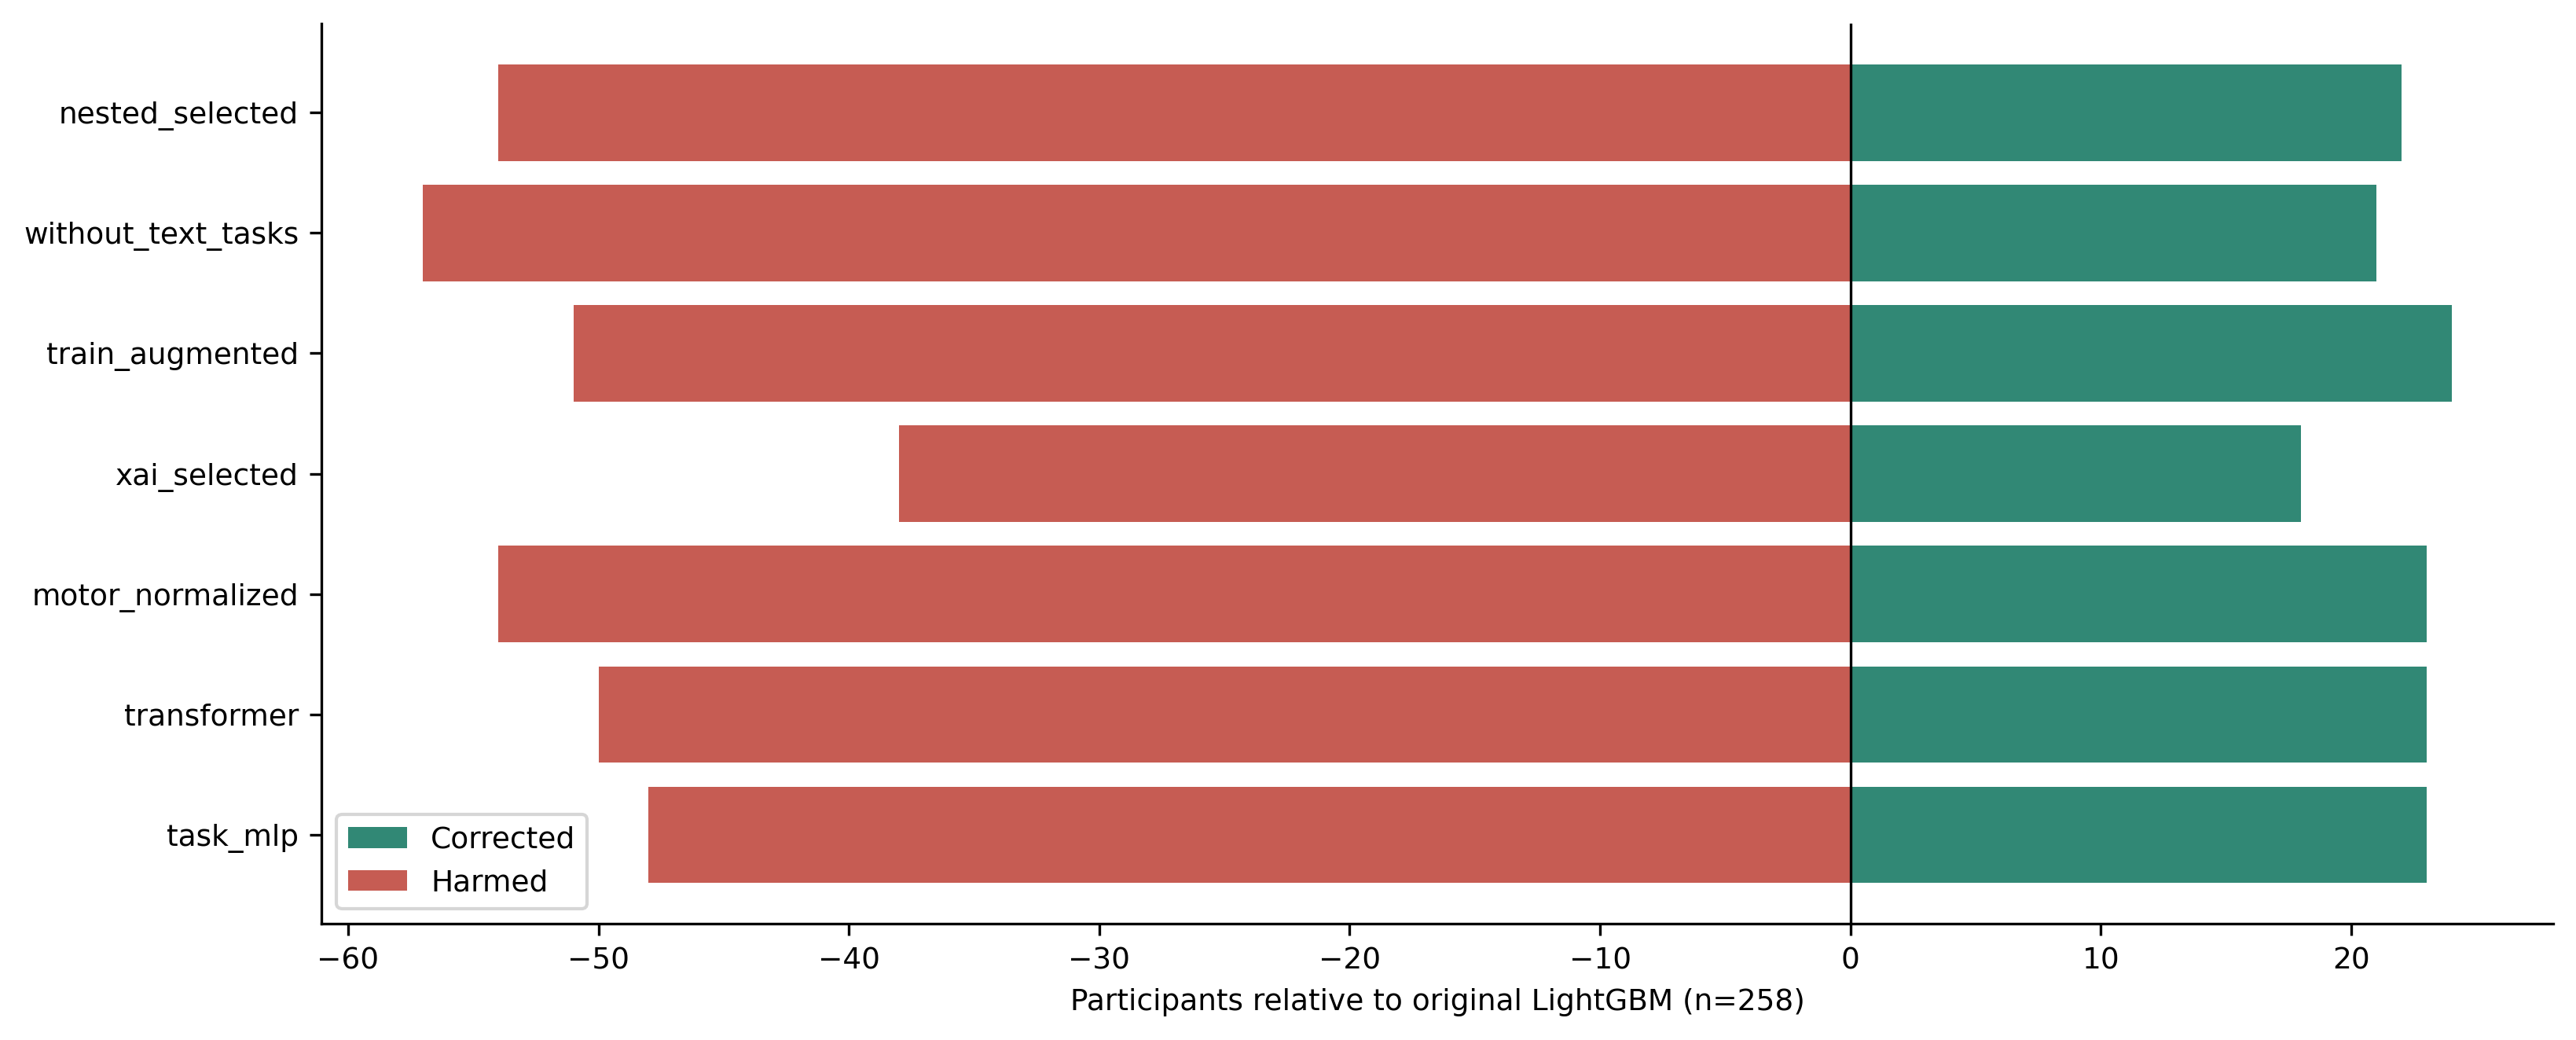

In [11]:
manifest=json.loads((OUT/'figures/manifest.json').read_text())
for f in manifest:
    display(Markdown('**'+f['name']+'** — '+f['caption']))
    display(Image(filename=str(OUT/'figures'/(f['name']+'.png')),width=1000))

## Giới hạn và trạng thái

Task1 đã xem cùng cohort/folds trước khi hình thành giả thuyết, nên train-only implementation không xóa research-level adaptive bias. Không có external/cross-language validation. Không coi ổn định XAI là đủ để bù accuracy thấp. Không dùng kết quả này làm chẩn đoán lâm sàng. Final `validation.json` được ghi sau khi notebook chạy và kiểm tra thành công.

In [12]:
display(Markdown('Trạng thái bàn giao cuối cùng: [validation.json](../results/task_transformer/validation.json). File được cập nhật sau khi notebook và unit tests vượt kiểm tra.'))
display(Markdown('Đọc kết luận đầy đủ tại [REPORT_VI.md](../results/task_transformer/REPORT_VI.md).'))

Trạng thái bàn giao cuối cùng: [validation.json](../results/task_transformer/validation.json). File được cập nhật sau khi notebook và unit tests vượt kiểm tra.

Đọc kết luận đầy đủ tại [REPORT_VI.md](../results/task_transformer/REPORT_VI.md).